# Writing-style analysis: *Sum Estimation via Vector Similarity Search*
**Mussmann, Raje, Tumkur, Messoussi, Hachem & Jacob. arXiv:2601.11765v1 (Jan 2026)**

This notebook measures the paper's prose and answers four questions, each with charts:

1. **Word choice, sentence structure and sentence length**
2. **Clarity and the logical flow of the argument**
3. **Tone and pacing**
4. **Audience density.** Which parts are dense for a lay reader and which for an AI expert, and what order each should read the paper in.

It then covers some extra checks: terminology consistency, whether the abstract's claims are backed up, how the figures and cross-references work, and a list of copy-edits. It ends with conclusions and recommendations.

**Method in brief.** PDF text extraction breaks up the mathematics. So the prose was transcribed into `paper_clean.txt` using the authors' exact wording, typos included. Inline maths is replaced by the token `⟨m⟩` and each display equation by an `[EQ]` line. As a cross-check, the maths density is also measured directly on the raw PDF text. All metrics are standard stylometric measures or transparent heuristics, defined where they're used. The audience scores are a model, not ground truth: they show *relative* density between sections.

In [1]:
import re, math
from collections import Counter
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.metrics.pairwise import cosine_similarity
import textstat
import style_lib as L

pd.set_option("display.max_colwidth", 160)
pd.set_option("display.width", 200)

# Palette: validated categorical order + one-hue sequential ramp + text inks.
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100",
         magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
         ink="#0b0b0b", ink2="#52514e", muted="#8a8984", grid="#e4e3df", surface="#fcfcfb")
SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
seq_cmap = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#fcfcfb"] + SEQ)
ROLE_COLOR = {"front": C["blue"], "method": C["orange"], "theory": C["aqua"],
              "experiments": C["yellow"], "context": C["magenta"], "appendix": C["green"]}
ROLE_NAME = {"front": "Front matter", "method": "Method", "theory": "Theory / proofs",
             "experiments": "Experiments", "context": "Related work & discussion",
             "appendix": "Appendix"}

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": C["surface"], "axes.facecolor": C["surface"],
    "savefig.facecolor": C["surface"], "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.labelcolor": C["ink2"],
    "axes.edgecolor": C["grid"], "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": C["grid"], "grid.linewidth": 0.6,
    "xtick.color": C["ink2"], "ytick.color": C["ink2"], "text.color": C["ink"],
    "legend.frameon": False, "lines.linewidth": 2,
})

def role_legend(ax, roles=None, **kw):
    roles = roles or list(ROLE_COLOR)
    ax.legend(handles=[Patch(color=ROLE_COLOR[r], label=ROLE_NAME[r]) for r in roles], **kw)

def subtitle(ax, text):
    ax.text(0, 1.02, text, transform=ax.transAxes, color=C["ink2"], fontsize=9, va="bottom")

## 0. Loading the paper and building the metric tables

In [2]:
sec, sen, captions = L.load_clean("paper_clean.txt")
sen = L.sentence_features(sen)
raw_math = L.raw_math_density("2601.11765v1.pdf")

sen["inline_math"] = sen.text.str.count("⟨m⟩")
sen["difficult"] = sen.text_nocite.map(lambda s: textstat.difficult_words(s.replace("⟨m⟩", "")))
sen["ml_jargon"] = sen.text_nocite.map(lambda s: L.count_terms(s, L.ML_JARGON))
sen["theory_jargon"] = sen.text_nocite.map(lambda s: L.count_terms(s, L.THEORY_JARGON))
sen["hedges"] = sen.text_nocite.map(lambda s: L.count_terms(s, L.HEDGES))
sen["boosters"] = sen.text_nocite.map(lambda s: L.count_terms(s, L.BOOSTERS))
ACRO_RE = re.compile(r"\b(?:[A-Z]{2,}[a-z]?|[A-Z][a-z]?[A-Z]+)\b")
sen["acronyms"] = sen.text_nocite.map(lambda s: len(ACRO_RE.findall(s)))
for kind, terms in L.CONNECTIVES.items():
    sen["conn_" + kind] = sen.text_nocite.map(lambda s, t=terms: L.count_terms(s, t))

def metrics(g, equations):
    w = g.words.sum()
    per100 = lambda col: 100 * g[col].sum() / max(w, 1)
    return pd.Series(dict(
        sentences=len(g), words=w, mean_len=g.words.mean(), median_len=g.words.median(),
        fk_grade=textstat.flesch_kincaid_grade(" ".join(g.text_nocite).replace("⟨m⟩", "")),
        difficult_pct=per100("difficult"), ml_jargon=per100("ml_jargon"),
        theory_jargon=per100("theory_jargon"), inline_math=per100("inline_math"),
        equations=equations, eq_per100=100 * equations / max(w, 1),
        acronyms=per100("acronyms"), passive_pct=100 * g.passive.mean(),
        we_pct=100 * g.we.mean(), nominal=per100("nominalizations"),
        clauses=g.clauses.mean(), citations=per100("citations"),
        hedges=per100("hedges"), boosters=per100("boosters"),
    ))

S = (sen.groupby("sid", sort=False)
        .apply(lambda g: metrics(g, int(sec.set_index("sid").loc[g.name, "equations"])), include_groups=False)
        .join(sec.set_index("sid")[["label", "role", "order"]])
        .join(raw_math.set_index("sid"))
        .sort_values("order"))
S["label_short"] = S.label.str.replace(r" \(intro\)", "", regex=True)
totals = dict(prose_words=int(S.words.sum()), sentences=int(S.sentences.sum()),
              display_equations=int(S.equations.sum()), inline_math=int(sen.inline_math.sum()),
              mean_sentence_len=round(sen.words.mean(), 1),
              median_sentence_len=float(sen.words.median()),
              fk_grade_overall=round(textstat.flesch_kincaid_grade(" ".join(sen.text_nocite).replace("⟨m⟩", "")), 1))
pd.Series(totals).to_frame("whole paper")

,whole paper
prose_words,3680.0
sentences,229.0
display_equations,79.0
inline_math,284.0
mean_sentence_len,16.1
median_sentence_len,14.0
fk_grade_overall,11.5


### Where the words go: a map of the paper
The left panel shows the prose word count per section. The right panel shows how much maths each section carries: display equations, plus maths symbols counted straight from the PDF as an independent check.

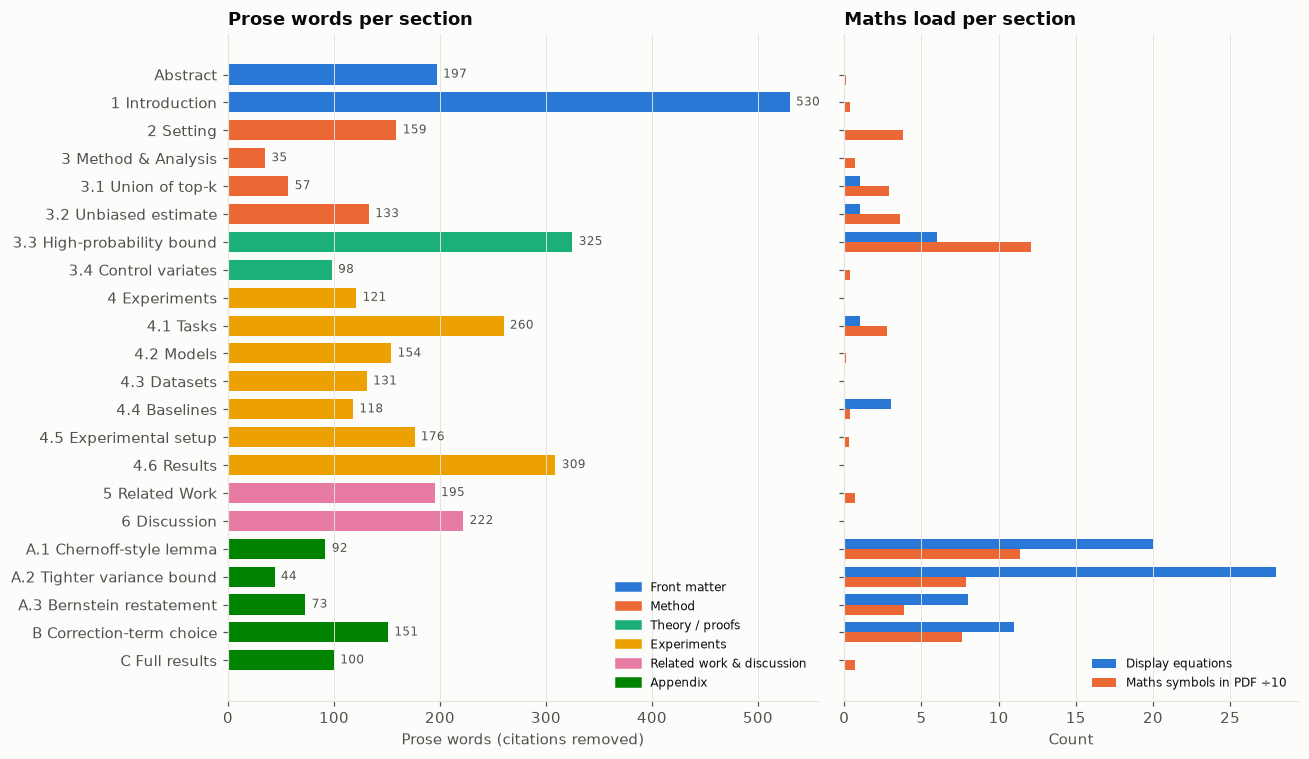

,% of prose words,% of display equations
role,,
Appendix,12.5,84.8
Related work & discussion,11.3,0.0
Experiments,34.5,5.1
Front matter,19.8,0.0
Method,10.4,2.5
Theory / proofs,11.5,7.6


In [3]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 7), sharey=True, gridspec_kw=dict(width_ratios=[1.3, 1]))
y = np.arange(len(S))[::-1]
a1.barh(y, S.words, color=[ROLE_COLOR[r] for r in S.role], height=0.72)
for yi, w in zip(y, S.words):
    a1.text(w + 6, yi, f"{int(w)}", va="center", fontsize=8, color=C["ink2"])
a1.set_yticks(y, S.label_short)
a1.set_xlabel("Prose words (citations removed)")
a1.set_title("Prose words per section")
role_legend(a1, loc="lower right", fontsize=8)
a1.grid(axis="y", visible=False)

a2.barh(y + 0.18, S.equations, height=0.36, color=C["blue"], label="Display equations")
a2.barh(y - 0.18, S.raw_math_symbols / 10, height=0.36, color=C["orange"], label="Maths symbols in PDF ÷10")
a2.set_title("Maths load per section")
a2.set_xlabel("Count")
a2.legend(loc="lower right", fontsize=8)
a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

share = S.groupby("role").words.sum() / S.words.sum() * 100
eq_share = S.groupby("role").equations.sum() / S.equations.sum() * 100
pd.DataFrame({"% of prose words": share.round(1), "% of display equations": eq_share.round(1)}).rename(index=ROLE_NAME)

**Reading the map.** The paper has about 3,700 words of prose, 79 display equations and about 280 inline maths expressions. Most of the prose is in the experiments sections (35%) and the front matter (20%). 85% of the display equations sit in Appendices A–B; Section 3.3 holds most of the rest. The main text is shaped like an *hourglass*: wordy, readable framing at both ends and a thin middle (Sections 2–3.2) that carries the actual algorithm in about 380 words. That middle is the paper's core idea, so its brevity is a strength for experts and a cliff for everyone else (see Q4).

---
# Q1. Word choice, sentence structure and sentence length

### 1a. Sentence length
Reference points: the US *Plain Language* guidelines aim for an average of 15–20 words. Academic science writing typically averages 22–26 words. Sentences over 35 words are where readers start to lose the thread.

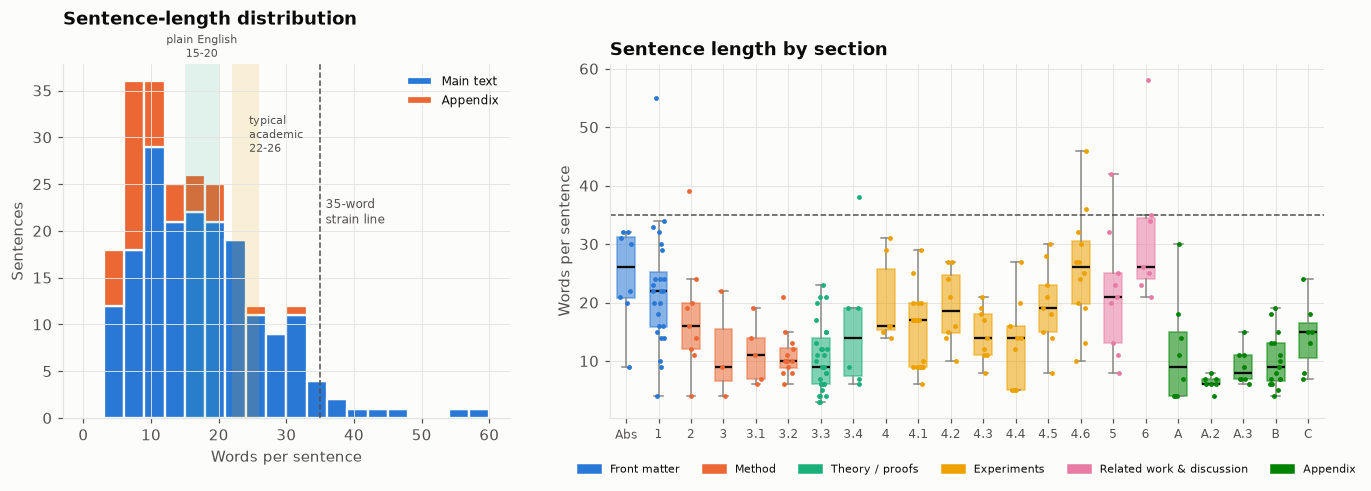

Main text: mean 17.5, median 16, 4% of sentences over 35 words; coefficient of variation 0.55


In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.6]))
bins = np.arange(0, 62, 3)
body = sen[sen.role.isin(["front", "method", "theory", "experiments", "context"])]
app = sen[sen.role == "appendix"]
a1.hist([body.words, app.words], bins=bins, stacked=True, color=[C["blue"], C["orange"]],
         edgecolor=C["surface"], linewidth=1.5, label=["Main text", "Appendix"])
a1.axvspan(15, 20, color=C["aqua"], alpha=.12, lw=0)
a1.axvspan(22, 26, color=C["yellow"], alpha=.14, lw=0)
a1.axvline(35, color=C["ink2"], lw=1, ls="--")
top_y = a1.get_ylim()[1]
a1.text(17.5, top_y * 1.01, "plain English\n15-20", ha="center", va="bottom", fontsize=7.5, color=C["ink2"])
a1.text(24.5, top_y * .86, "typical\nacademic\n22-26", ha="left", va="top", fontsize=7.5, color=C["ink2"])
a1.text(35.8, top_y * .55, "35-word\nstrain line", fontsize=8, color=C["ink2"])
a1.set_xlabel("Words per sentence"); a1.set_ylabel("Sentences")
a1.set_title("Sentence-length distribution", pad=26); a1.legend(loc="upper right", fontsize=8)

order = list(S.index)
data = [sen.loc[sen.sid == s, "words"].values for s in order]
pos = np.arange(len(order))
bp = a2.boxplot(data, positions=pos, widths=.55, patch_artist=True, showfliers=False,
                medianprops=dict(color=C["ink"], lw=1.5), whiskerprops=dict(color=C["muted"]),
                capprops=dict(color=C["muted"]))
for patch, r in zip(bp["boxes"], S.role):
    patch.set(facecolor=ROLE_COLOR[r], alpha=.55, edgecolor=ROLE_COLOR[r])
rng = np.random.default_rng(0)
for p, d, r in zip(pos, data, S.role):
    a2.scatter(p + rng.uniform(-.18, .18, len(d)), d, s=10, color=ROLE_COLOR[r], zorder=3, lw=0)
a2.axhline(35, color=C["ink2"], lw=1, ls="--")
a2.set_xticks(pos, order, rotation=0, fontsize=8)
a2.set_ylabel("Words per sentence"); a2.set_title("Sentence length by section")
role_legend(a2, loc="upper center", ncol=6, fontsize=7.5, bbox_to_anchor=(.5, -.1))
plt.tight_layout(); plt.show()

print(f"Main text: mean {body.words.mean():.1f}, median {body.words.median():.0f}, "
      f"{(body.words>35).mean()*100:.0f}% of sentences over 35 words; "
      f"coefficient of variation {body.words.std()/body.words.mean():.2f}")

In [5]:
long = sen[sen.words >= 35].sort_values("words", ascending=False)[["sid", "words", "clauses", "citations", "text"]]
long.style.hide(axis="index").set_caption("Sentences of 35+ words (candidates for splitting)")

sid,words,clauses,citations,text
6,58,3,0,"Because HNSW methods make use of randomly assigned levels with exponentially decaying probabilities, and for each query execution iteratively find a (approximate) most similar vector within each level, it is likely that a slightly modified HNSW algorithm could return the similar vectors at every level for a single query, significantly cutting the total computation time of our method."
1,55,2,0,"In this work, we assume access to a maximization oracle: given a non-negative function ⟨m⟩ (eg, the exponentiation of the negative squared Euclidean distance for KDE with Gaussian kernel) and a set of ⟨m⟩ objects ⟨m⟩, the oracle builds a data-structure that allows it to quickly compute ⟨m⟩ based on a query ⟨m⟩, and more generally, retrieve the top-k objects."
4.6,46,4,0,"Note that the runtime for our method does not scale linearly with ⟨m⟩; in Section 6 we discuss a relatively straightforward opportunity to integrate HNSW methods and our proposed method to improve the runtime, taking advantage of the fact that HNSW also uses random levels with exponentially-decaying probabilities."
5,42,3,1,"Locality sensitive hashing (LSH) (Indyk and Motwani, 1998; Charikar, 2002; Lv et al, 2007; Andoni and Indyk, 2008; Andoni et al, 2015) is a set of vector similarity search techniques that are perhaps the only class of methods which have theoretical guarantees (and avoid an exponential dependence on the dimension), though clustering-based methods and proximity-graph-based methods empirically perform much better."
2,39,3,0,"While we can exactly compute the sum via a linear scan, here, we leverage a black-box maximization oracle, for example a vector similarity search technique, which, given a pre-computed data-structure, can empirically be much faster than a linear scan."
3.4,38,2,0,"In Appendix B, we motivate selecting ⟨m⟩ as the average value of the lower half of the ⟨m⟩ values: ⟨m⟩, which can be estimated from a uniform random sample (the union of elements on unfilled levels is a uniform random sample)."
4.6,36,1,0,"To illustrate the performance of methods with respect to the flatness/peakiness, we present the median relative error as a function of the bandwidth for KDE on Open Images for the four methods in Figure 2(a)."
6,35,2,0,"One limitation of our use of a black-box maximization oracle in the design of the algorithm is that our performance guarantee is in terms of the number of retrieved similar vectors, rather than total runtime."


**Findings on sentence length**
- The paper's average sentence (16 words overall, 17.5 in the main text) is **shorter than typical academic prose** and inside the plain-English band. Only 4% of main-text sentences exceed 35 words. The authors are economical writers.
- Sentence length varies a lot (coefficient of variation 0.55), which keeps the rhythm from going monotonous. But the variation is **split by section** rather than mixed within paragraphs. The framing sections (Abstract, Introduction, 4.6 Results, 6 Discussion) run at 22–26 words a sentence. The method and proof sections run at 10–12, because maths carries the content and the prose turns into short connective statements ("Define …", "Then, …").
- The long tail is just 8 sentences, listed above, and they come in three types. All are easy to split.
  - *Clause chains* (the HNSW-integration sentence in Section 6, at 58 words; the runtime and bandwidth sentences in 4.6; the limitation sentence in Section 6) stack 2–4 clauses before the main point lands.
  - *Definitions packed with examples* (the maximization-oracle sentence in the Introduction, at 55 words; the linear-scan sentence in Section 2; the correction-term sentence in 3.4) carry a definition, an example and a consequence all in one sentence.
  - *Citation trains.* The table counts words with citations removed. With them, the Introduction's opening sentence runs to 66 words across 11 references, and the LSH sentence in Related Work carries 5 references in one parenthesis. Readers experience the raw length.

### 1b. Word choice: vocabulary, word length and lexical variety

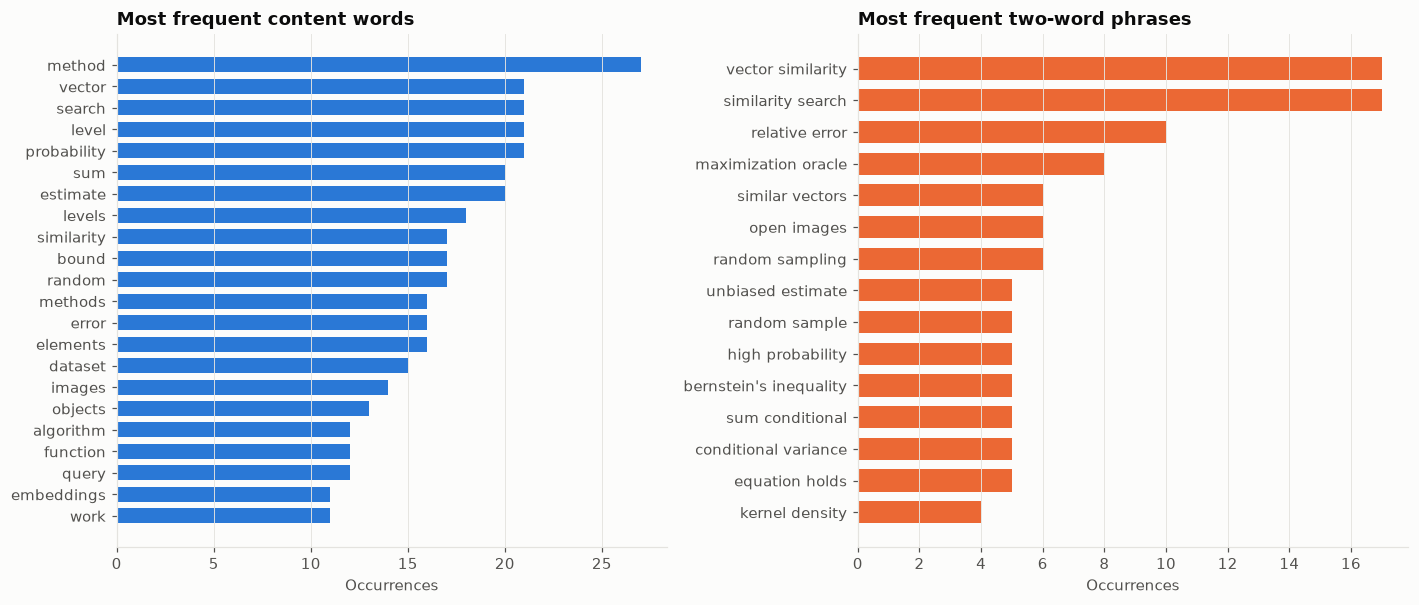

In [6]:
STOP = set(ENGLISH_STOP_WORDS) | {"eg", "ie", "et", "al", "let", "use", "using", "used", "given", "define", "uses"}
toks = [w.lower() for s in sen.text_nocite for w in L.words(s)]
content = [w for w in toks if w not in STOP and len(w) > 2]
top = Counter(content).most_common(22)

bigr = Counter()
for s in sen.text_nocite:
    ws = [w.lower() for w in L.words(s)]
    for a, b in zip(ws, ws[1:]):
        if a not in STOP and b not in STOP and len(a) > 2 and len(b) > 2:
            bigr[(a, b)] += 1
topb = bigr.most_common(15)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 5.6))
w, c = zip(*top[::-1])
a1.barh(w, c, color=C["blue"], height=.7); a1.set_title("Most frequent content words"); a1.set_xlabel("Occurrences")
a1.grid(axis="y", visible=False)
b, cb = zip(*topb[::-1])
a2.barh([" ".join(x) for x in b], cb, color=C["orange"], height=.7); a2.set_title("Most frequent two-word phrases")
a2.set_xlabel("Occurrences"); a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

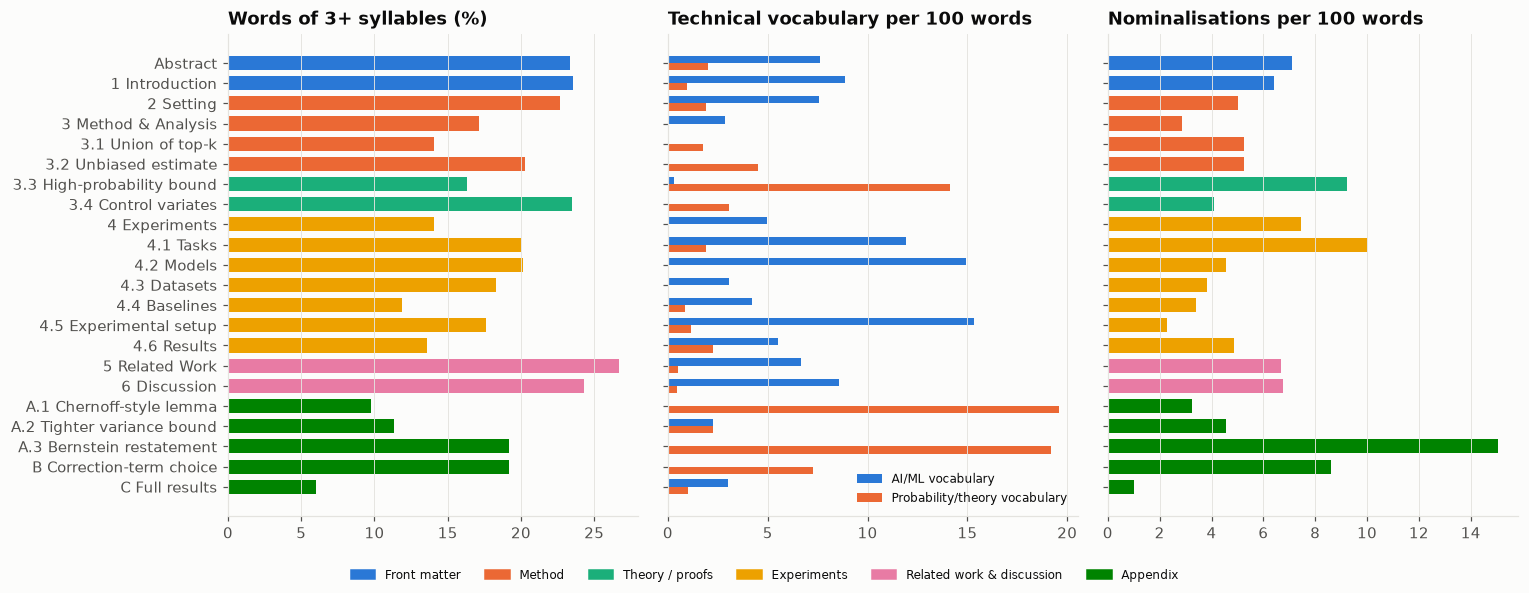

Whole-paper MTLD (lexical diversity): 65  (roughly 70-90 is common for scientific prose; higher = more varied vocabulary)


In [7]:
def mtld(tokens, threshold=0.72):
    # Measure of Textual Lexical Diversity (McCarthy & Jarvis, 2010), averaged over both directions.
    def one(seq):
        factors, types, count = 0.0, set(), 0
        for t in seq:
            count += 1; types.add(t)
            if len(types) / count <= threshold:
                factors += 1; types, count = set(), 0
        if count:
            factors += (1 - len(types) / count) / (1 - threshold)
        return len(seq) / factors if factors else float("nan")
    return (one(tokens) + one(tokens[::-1])) / 2

rows = []
for sid, g in sen.groupby("sid", sort=False):
    t = [w.lower() for s in g.text_nocite for w in L.words(s)]
    syl = [textstat.syllable_count(x) for x in t]
    rows.append(dict(sid=sid, mtld=mtld(t) if len(t) > 50 else np.nan,
                     long_word_pct=100 * np.mean([s >= 3 for s in syl]),
                     mean_word_len=np.mean([len(x) for x in t])))
W = pd.DataFrame(rows).set_index("sid").join(S[["label_short", "role", "nominal", "ml_jargon", "theory_jargon", "difficult_pct"]])

fig, axes = plt.subplots(1, 3, figsize=(14, 5.4), sharey=True)
y = np.arange(len(W))[::-1]
cols = [W.role.map(ROLE_COLOR)]
axes[0].barh(y, W.long_word_pct, color=cols[0], height=.7)
axes[0].set_title("Words of 3+ syllables (%)")
axes[1].barh(y + .18, W.ml_jargon, height=.36, color=C["blue"], label="AI/ML vocabulary")
axes[1].barh(y - .18, W.theory_jargon, height=.36, color=C["orange"], label="Probability/theory vocabulary")
axes[1].set_title("Technical vocabulary per 100 words"); axes[1].legend(fontsize=8, loc="lower right")
axes[2].barh(y, W.nominal, color=cols[0], height=.7)
axes[2].set_title("Nominalisations per 100 words")
axes[0].set_yticks(y, W.label_short)
for a in axes: a.grid(axis="y", visible=False)
fig.legend(handles=[Patch(color=ROLE_COLOR[r], label=ROLE_NAME[r]) for r in ROLE_COLOR], loc="lower center", ncol=6, fontsize=8)
plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()
print(f"Whole-paper MTLD (lexical diversity): {mtld([w.lower() for s in sen.text_nocite for w in L.words(s)]):.0f}  "
      "(roughly 70-90 is common for scientific prose; higher = more varied vocabulary)")

In [8]:
# Acronyms: where each is first used versus where (if anywhere) it is expanded.
text_all = " ".join(sen.text)
acros = ["KDE", "LSH", "HNSW", "CLIP", "ViT", "BERT", "DistilBERT", "AWS", "RAM", "GB", "pdf", "KL"]
rows = []
for a in acros:
    hits = sen[sen.text.str.contains(rf"\b{re.escape(a)}\b")]
    defined = sen[sen.text.str.contains(rf"\(\s*{re.escape(a)}\s*\)")]
    rows.append(dict(acronym=a, uses=int(sen.text.str.count(rf"\b{re.escape(a)}\b").sum()),
                     first_used=hits.sid.iloc[0] if len(hits) else "-",
                     expanded_in=defined.sid.iloc[0] if len(defined) else "never"))
acro_df = pd.DataFrame(rows)
acro_df.style.hide(axis="index").set_caption("Acronyms: first use and expansion")

acronym,uses,first_used,expanded_in
KDE,10,Abs,Abs
LSH,6,1,1
HNSW,8,1,1
CLIP,5,4.2,never
ViT,2,4.2,4.2
BERT,4,4.2,never
DistilBERT,3,4.2,never
AWS,2,4,never
RAM,2,4,never
GB,2,4,never


**Findings on word choice**
- **The vocabulary is precise and repetitive by design.** *Vector similarity search* (17 times, the most frequent phrase), *relative error*, *maximization oracle* and *top-k* recur as fixed technical labels, and the authors avoid "elegant variation" (swapping in synonyms for the same thing). That consistency is good for clarity, and it explains why lexical diversity (MTLD about 65) sits slightly *below* the usual range for scientific prose. The cost is heaviness: a 3-word noun phrase repeated 17 times. Coining a short form once ("VSS") would lighten the Introduction, Section 5 and Section 6.
- **Plain verbs, little puffery.** The verbs that do the work are *define, compute, estimate, retrieve, show, prove*. Nominalisations (nouns built from verbs, such as *estimation*, *exponentiation*, *instantiation*) peak in 4.1 Tasks, 3.3, the Abstract and the Introduction. In the front matter, that noun-heavy style is what makes sentences long (see 1c).
- **Two vocabularies, cleanly separated.** AI/ML vocabulary (*embedding, softmax, HNSW, CLIP*) dominates the Introduction and Section 4. Probability vocabulary (*martingale, filtration, Bernstein, union bound*) is fenced into 3.3 and the appendix. A reader can therefore pick a lane.
- **Acronym hygiene is mostly good.** KDE, LSH, HNSW and ViT are expanded on first use. **CLIP and BERT are never expanded**, which is standard for ML readers but opaque to anyone else. *AWS/RAM/GB* are fine.

### 1c. Sentence structure

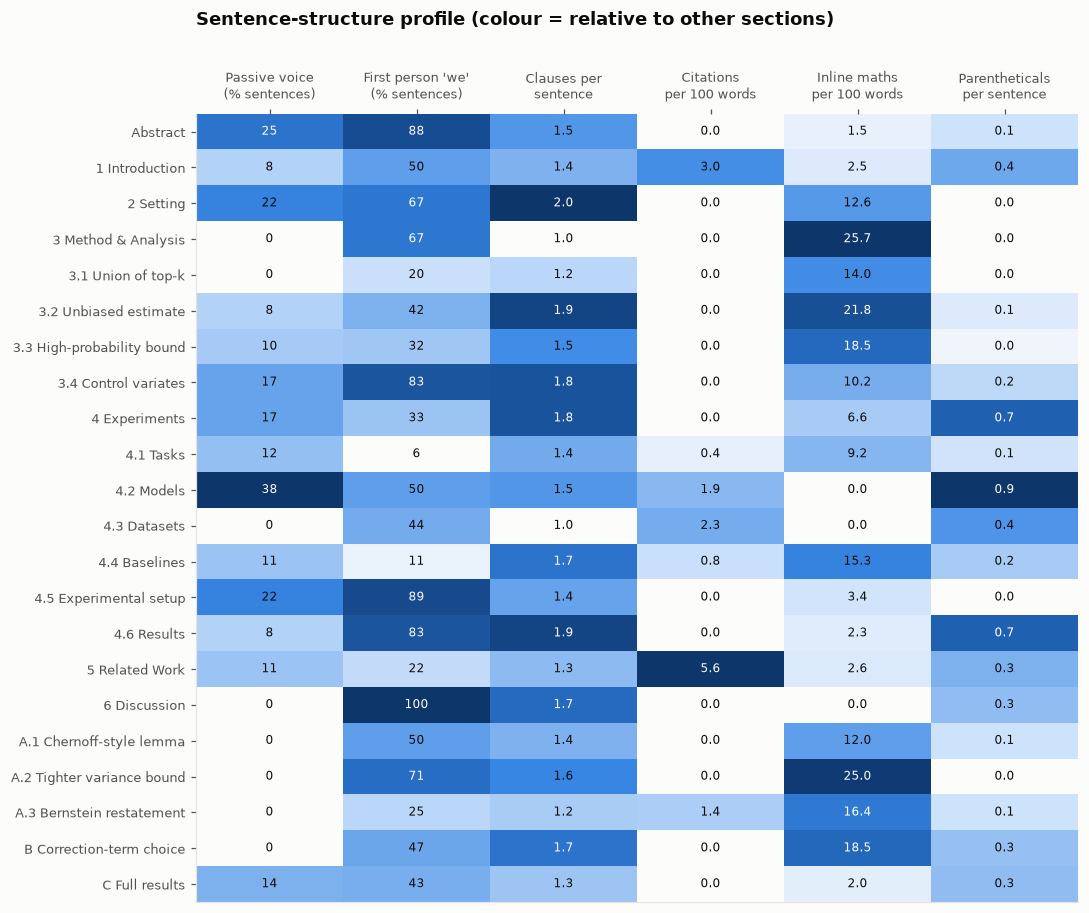

In [9]:
struct = S[["passive_pct", "we_pct", "clauses", "citations", "inline_math"]].copy()
struct["parenthetical"] = sen.groupby("sid", sort=False).parens.mean().reindex(S.index)
struct.columns = ["Passive voice\n(% sentences)", "First person 'we'\n(% sentences)",
                  "Clauses per\nsentence", "Citations\nper 100 words", "Inline maths\nper 100 words",
                  "Parentheticals\nper sentence"]
norm = (struct - struct.min()) / (struct.max() - struct.min())
fig, ax = plt.subplots(figsize=(10, 8.4))
ax.imshow(norm.values, cmap=seq_cmap, aspect="auto", vmin=0, vmax=1)
for i in range(struct.shape[0]):
    for j in range(struct.shape[1]):
        v = struct.values[i, j]
        ax.text(j, i, f"{v:.0f}" if struct.columns[j].startswith(("Passive", "First")) else f"{v:.1f}",
                ha="center", va="center", fontsize=8, color=C["ink"] if norm.values[i, j] < .6 else "white")
ax.set_xticks(range(struct.shape[1]), struct.columns, fontsize=8.5)
ax.set_yticks(range(len(S)), S.label_short, fontsize=8.5)
ax.xaxis.tick_top(); ax.grid(False)
ax.set_title("Sentence-structure profile (colour = relative to other sections)", pad=58)
plt.tight_layout(); plt.show()

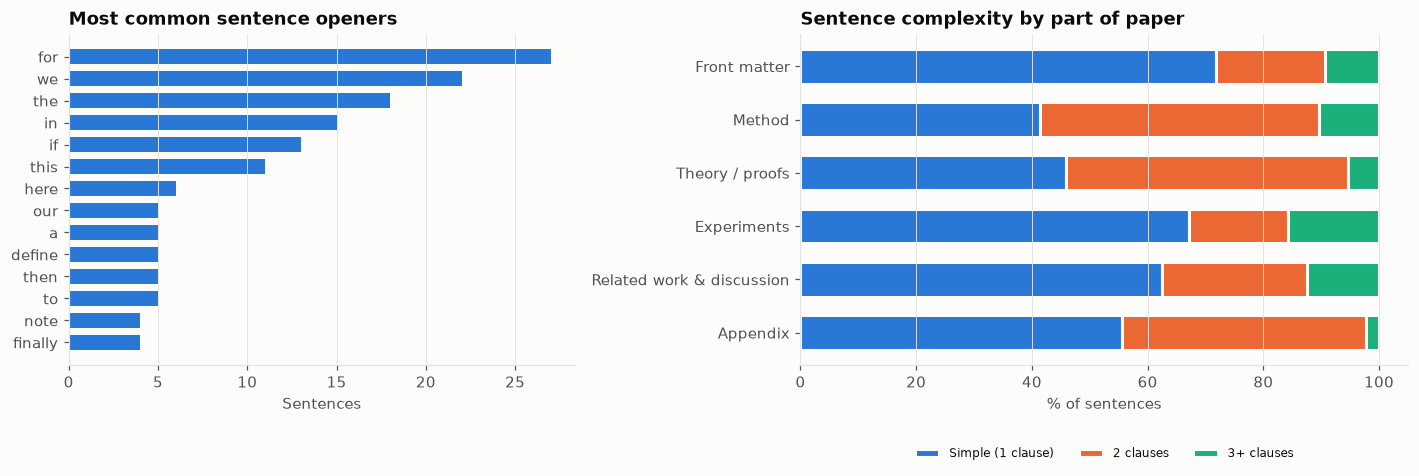

In [10]:
openers = Counter(sen.opener.str.lower())
top_open = openers.most_common(14)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw=dict(width_ratios=[1, 1.2]))
o, c = zip(*top_open[::-1])
a1.barh(o, c, color=C["blue"], height=.7); a1.set_title("Most common sentence openers"); a1.set_xlabel("Sentences")
a1.grid(axis="y", visible=False)

# Sentence shape: simple / with one subordinate clause / multi-clause
shape = pd.cut(sen.clauses, [0, 1, 2, 99], labels=["Simple (1 clause)", "2 clauses", "3+ clauses"])
tab = pd.crosstab(sen.role, shape, normalize="index").reindex(list(ROLE_COLOR)) * 100
left = np.zeros(len(tab))
for col, colr in zip(tab.columns, [C["blue"], C["orange"], C["aqua"]]):
    a2.barh(tab.index.map(ROLE_NAME), tab[col], left=left, color=colr, label=col, height=.65,
            edgecolor=C["surface"], linewidth=2)
    left += tab[col].values
a2.invert_yaxis(); a2.set_xlabel("% of sentences"); a2.set_title("Sentence complexity by part of paper")
a2.legend(loc="lower center", bbox_to_anchor=(.5, -.32), ncol=3, fontsize=8); a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

**Findings on sentence structure**
- **Active, first-person voice dominates.** 47% of sentences use *we/our/us* (100% in the Discussion, about 85% in the Abstract, 4.5 and 4.6). Passive voice appears in only about 10%, low for a theory-plus-experiments paper. The prose reads as authors walking you through their work, which aids clarity. The passive clusters in 4.2 Models (38%: "is trained on", "obtained through"), where it is appropriate.
- **Openers are formulaic but functional.** *For*, *We*, *The*, *In*, *If* and *This* open most sentences. In the method and proof sections the rhythm ("Define … If … Then … Thus …") mirrors mathematical style and suits it. In the Abstract, 6 of 8 sentences open with *We/Our/With* or *In this work, we*, a slightly monotone cadence.
- **Parentheticals are a habit.** The paper leans on brackets for definitions, licences, examples and asides. Section 4.2 averages about one per sentence (licences, model sizes), and 4.6 and the Section 4 intro about 0.7. They are fine for experts, but they interrupt the sentence for lay readers. Licence details (*Apache 2.0 license*, *CC BY 4.0*) could go into a single footnote or appendix table.
- **Long ≠ complex.** The front matter has the *longest* sentences, yet about 70% of them are single-clause. Their length comes from stacked noun phrases and lists ("words and tokens (…), sentences and documents (…), images (…), audio clips (…), videos (…)") rather than nested reasoning. The method and theory sections are the opposite: short sentences, but more than half carry a subordinate clause (*if, where, since, which*), because definitions and conditions are packed in. So lay readers face long-but-flat sentences up front, and short-but-dense ones in the middle.

---
# Q2. Clarity and logical flow

### 2a. Readability by section
The Flesch–Kincaid grade estimates the US school grade needed to follow the prose, computed with maths tokens removed. Here it is paired with how much maths the section carries, because maths is an extra cost that a prose readability formula can't see.

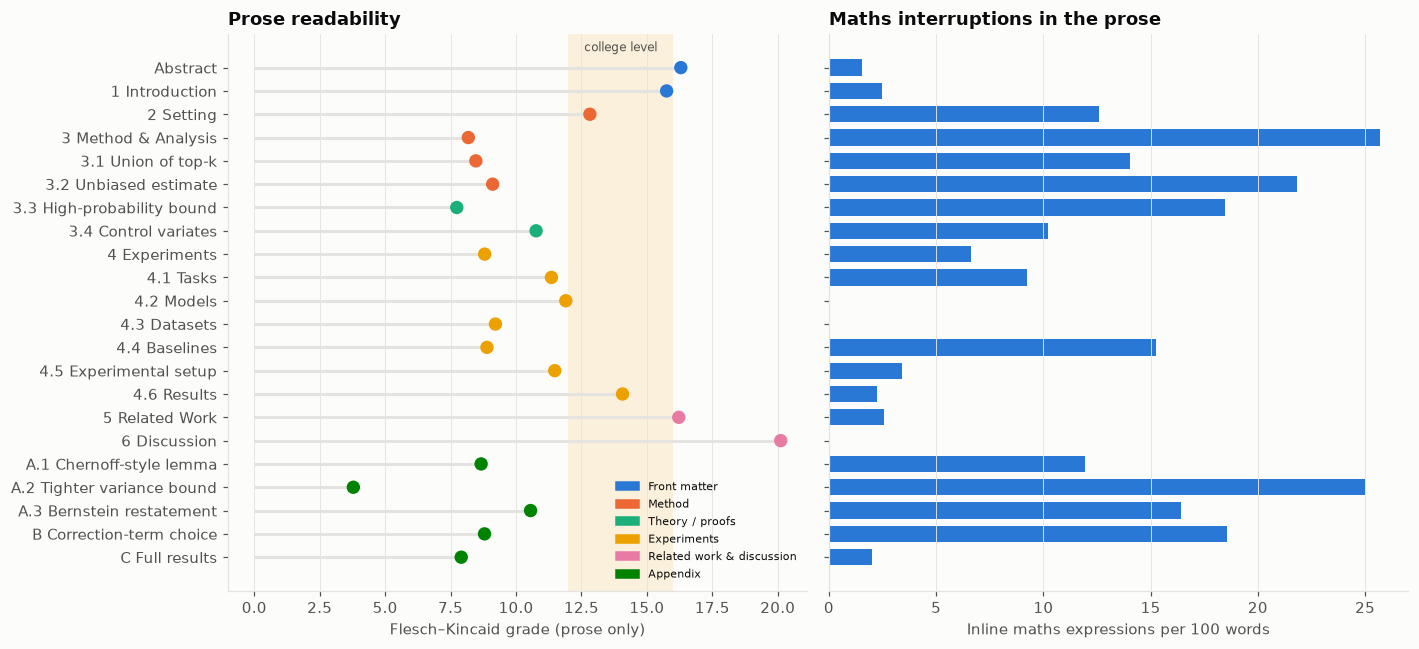

In [11]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6), sharey=True)
y = np.arange(len(S))[::-1]
a1.hlines(y, 0, S.fk_grade, color=C["grid"], lw=2)
a1.scatter(S.fk_grade, y, s=60, color=[ROLE_COLOR[r] for r in S.role], zorder=3)
a1.axvspan(12, 16, color=C["yellow"], alpha=.12, lw=0)
a1.text(14, len(S) - .3, "college level", ha="center", fontsize=8, color=C["ink2"])
a1.set_yticks(y, S.label_short); a1.set_xlabel("Flesch–Kincaid grade (prose only)")
a1.set_title("Prose readability"); a1.grid(axis="y", visible=False)
a2.barh(y, S.inline_math, color=C["blue"], height=.7)
a2.set_xlabel("Inline maths expressions per 100 words"); a2.set_title("Maths interruptions in the prose")
a2.grid(axis="y", visible=False)
role_legend(a1, loc="lower right", fontsize=7.5)
plt.tight_layout(); plt.show()

The two panels mirror each other. **The sections that read hardest as prose (Abstract, Introduction, Related Work, Discussion: grade 16–20) contain almost no maths. The sections with the easiest prose (3.x and the appendix: grade 4–11) carry 10–26 inline maths expressions per 100 words.** The overall grade is 11.5, but that average hides the trade-off. The only sections easy on *both* counts are 4.2–4.3 and 4.6, the descriptive parts of the experiments. Everywhere else the reader pays either in sentence complexity or in notation. The low grades in Section 3 flatter it, because "Then, ⟨m⟩." scores as easy text.

### 2b. Logical connectives: how explicitly is the reasoning signposted?

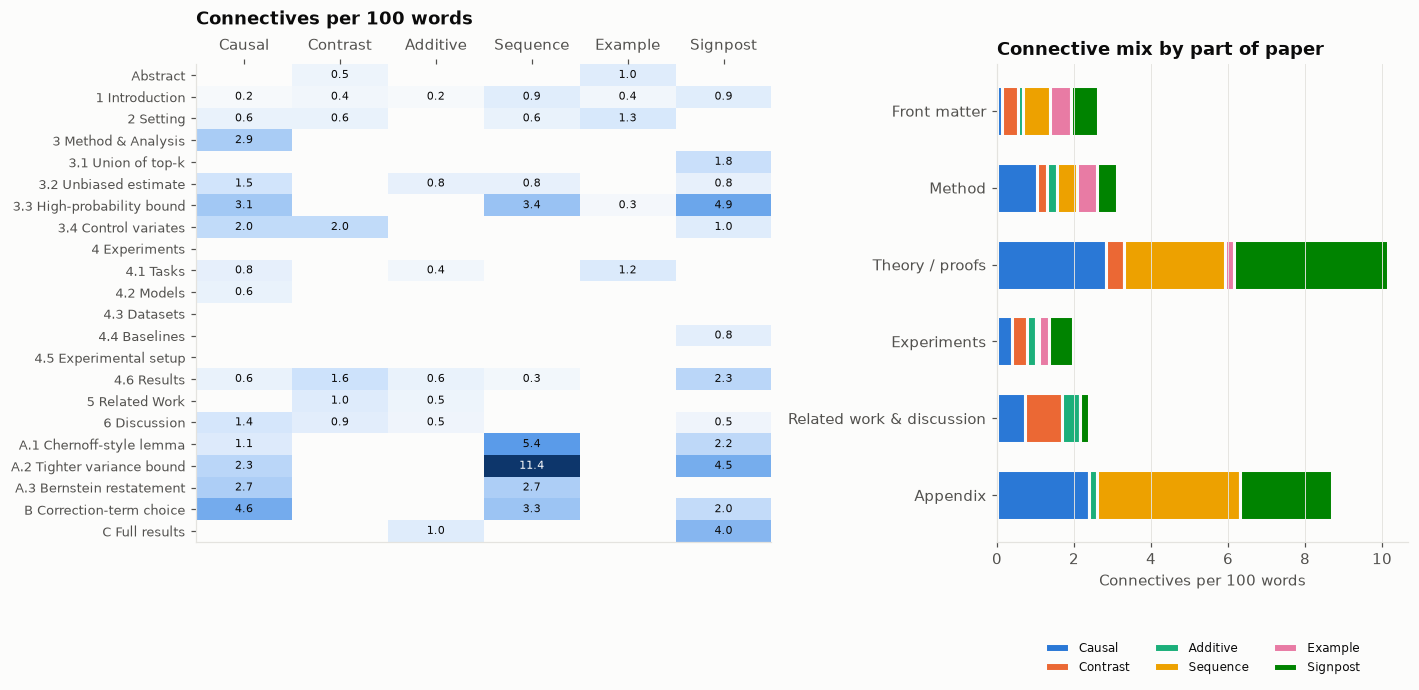

In [12]:
conn_cols = [c for c in sen.columns if c.startswith("conn_")]
CONN = sen.groupby("sid", sort=False)[conn_cols].sum().div(S.words, axis=0) * 100
CONN.columns = [c[5:].capitalize() for c in conn_cols]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.6), gridspec_kw=dict(width_ratios=[1.4, 1]))
im = a1.imshow(CONN.values, cmap=seq_cmap, aspect="auto")
for i in range(CONN.shape[0]):
    for j in range(CONN.shape[1]):
        v = CONN.values[i, j]
        if v > 0: a1.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7.5,
                          color="white" if v > CONN.values.max() * .55 else C["ink"])
a1.set_xticks(range(CONN.shape[1]), CONN.columns); a1.set_yticks(range(len(S)), S.label_short, fontsize=8.5)
a1.xaxis.tick_top(); a1.grid(False); a1.set_title("Connectives per 100 words", pad=26)
tot = sen.groupby("role")[conn_cols].sum()
tot = tot.div(S.groupby("role").words.sum(), axis=0) * 100
tot.columns = CONN.columns
tot = tot.reindex(list(ROLE_COLOR))
left = np.zeros(len(tot))
pal = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["green"]]
for col, colr in zip(tot.columns, pal):
    a2.barh(tot.index.map(ROLE_NAME), tot[col], left=left, color=colr, label=col, height=.65,
            edgecolor=C["surface"], linewidth=2)
    left += tot[col].values
a2.invert_yaxis(); a2.set_xlabel("Connectives per 100 words"); a2.grid(axis="y", visible=False)
a2.set_title("Connective mix by part of paper")
a2.legend(loc="lower center", bbox_to_anchor=(.5, -.3), ncol=3, fontsize=8)
plt.tight_layout(); plt.show()

**Findings.** The reasoning is **explicit where the maths is and implicit where the prose is**. The theory sections and appendix run at 8–10 connectives per 100 words: causal (*since, thus, so*), sequencing (*first, then, finally*) and signposts to lemmas and equations. That is a well-walked proof. The front matter, experiments and related work run at only about 2–3 per 100 words. Those parts read as a sequence of statements, and the reader must infer *why* one sentence follows another. **Contrast markers are among the scarcest types**, even though the paper's main claim is comparative (O(log n) against O(√n), lower error than the combined baseline). Section 4.6 has the most contrast markers (*while, except, unlike*), which is right. But the Introduction states the gap with a single "Unfortunately", and Related Work positions the paper mostly by listing ("In comparison…", "differs"). A sharper "prior methods do X; we do Y, which buys Z" line would make the contribution land faster.

### 2c. Sentence-to-sentence cohesion
The overlap between each sentence's content words (TF-IDF) and those of the sentence before it. High values mean each sentence picks up where the last left off. Dips mark topic jumps.

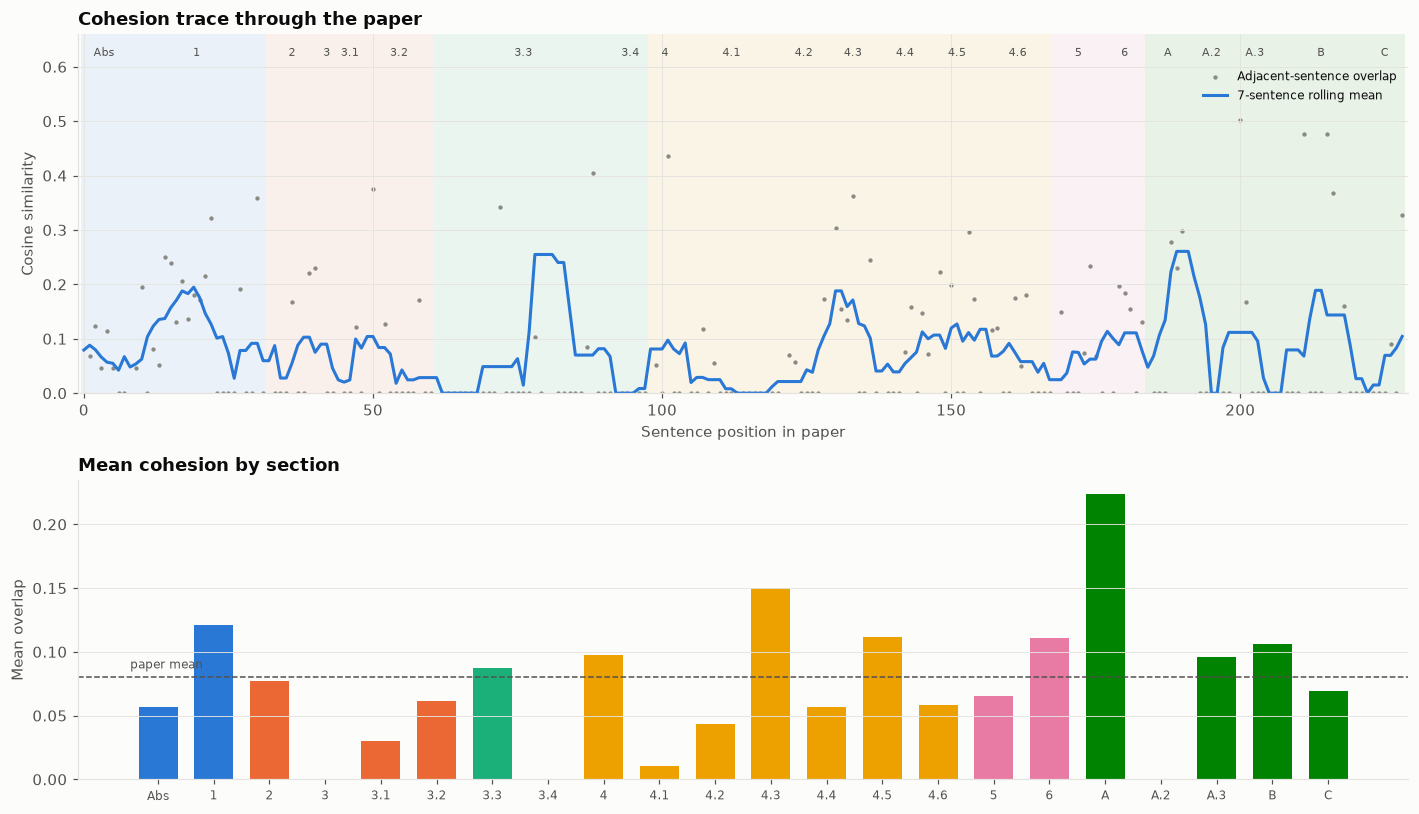

sid,text
Abs,"We show results on applications in estimating densities, computing softmax denominators, and counting the number of vectors within a ball."
Abs,Our partially redacted code can be found at URL.
1,"In this work, we study a related set of problems that involve computing or estimating a sum over all elements in a dataset."
1,"For a query ⟨m⟩, we retrieve the top-k objects from each level, and compute an unbiased estimate using a simple algorithm (see details in Section 3.2)."
1,We present experimental results showing the effectiveness of our method for sum estimation tasks on Open Images and Amazon Reviews.
1,Our contributions are several:
1,Show an estimator of the sum given the top-k elements from each exponentially-sampled level.
1,Introduce an additional sum estimation application: counting the number of elements within a ball.
1,Present experimental results that demonstrate the effectiveness of our method.
1,"Finally, we conclude by covering related work and a opportunities and limitations in Sections 5 and 6."


In [13]:
vec = TfidfVectorizer(stop_words=list(STOP), token_pattern=r"[A-Za-z][A-Za-z\-]+", sublinear_tf=True)
X = vec.fit_transform(sen.text_nocite.str.replace("⟨m⟩", " ", regex=False))
sim = np.array([np.nan] + [cosine_similarity(X[i - 1], X[i])[0, 0] for i in range(1, X.shape[0])])
same = sen.sid.values[1:] == sen.sid.values[:-1]
sim[1:][~same] = np.nan          # do not score jumps across section boundaries
sen["cohesion"] = sim

coh = sen.groupby("sid", sort=False).cohesion.mean().reindex(S.index)
roll = sen.cohesion.rolling(7, min_periods=3, center=True).mean()

fig, (a1, a2) = plt.subplots(2, 1, figsize=(13, 7.5), gridspec_kw=dict(height_ratios=[1.2, 1]))
for sid, g in sen.groupby("sid", sort=False):
    a1.axvspan(g.pos.min() - .5, g.pos.max() + .5, color=ROLE_COLOR[g.role.iloc[0]], alpha=.08, lw=0)
    a1.text((g.pos.min() + g.pos.max()) / 2, .62, sid, ha="center", fontsize=7, color=C["ink2"])
a1.scatter(sen.pos, sen.cohesion, s=8, color=C["muted"], lw=0, label="Adjacent-sentence overlap")
a1.plot(sen.pos, roll, color=C["blue"], label="7-sentence rolling mean")
a1.set_ylim(0, .66); a1.set_xlim(-1, len(sen)); a1.set_xlabel("Sentence position in paper")
a1.set_ylabel("Cosine similarity"); a1.set_title("Cohesion trace through the paper")
a1.legend(loc="upper right", fontsize=8, bbox_to_anchor=(1, .93))

y = np.arange(len(coh))
a2.bar(y, coh.values, color=[ROLE_COLOR[r] for r in S.role], width=.7)
a2.axhline(np.nanmean(sen.cohesion), color=C["ink2"], lw=1, ls="--")
a2.text(-.5, np.nanmean(sen.cohesion) + .004, "paper mean", ha="left", va="bottom", fontsize=8, color=C["ink2"])
a2.set_xticks(y, S.index, fontsize=8); a2.set_ylabel("Mean overlap"); a2.set_title("Mean cohesion by section")
a2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

low = sen[(sen.cohesion < .02) & sen.role.isin(["front", "method", "experiments", "context"])]
low[["sid", "text"]].head(10).style.hide(axis="index").set_caption("Sentences with ~zero overlap with the preceding sentence (main text)")

**Findings.** *(Caveat: the measure only sees words, so in maths-heavy sections the link carried by symbols is invisible and scores read low.)*
- **Best-knit prose: the Introduction, 4.3 Datasets, 4.5 Setup and 6 Discussion.** Each paragraph develops one object and repeats its key nouns, so a reader is never lost about the topic.
- **Weakest: 4.1 Tasks, 3.1 and 4.2 Models.** 4.1 jumps between three tasks (KDE → softmax → counting), and inside each it alternates a prose sentence with a formula sentence ("Here, ⟨m⟩ is 'peaky' for small ⟨m⟩"). The three paragraphs share a template but never say so. One framing sentence ("Each task is a sum of a monotone function of distance or similarity, so a vector search can find its largest terms") would tie them together and tell the reader *why these three*.
- **Topic jumps sit at paragraph starts, as they should.** The near-zero dips in the trace are mostly the first sentence of a new run-in paragraph (Models, Datasets, Baselines), which is acceptable in reference-style sections. The one costly jump is in the Introduction: paragraph 1 surveys embeddings → search algorithms → commercial systems, and the *sum* problem arrives only in paragraph 2. A bridging sentence ("Many downstream tasks need not just the nearest items but an aggregate over *all* items …") would join them.

### 2d. Cross-reference flow: does the paper point forwards or backwards?
Each arc is an explicit reference (Section/Appendix/Figure/Algorithm/Lemma/Theorem/Equation) from where it is written to where its target lives. **Forward** references (above the axis) ask the reader to trust something not yet shown. **Backward** references (below) consolidate.

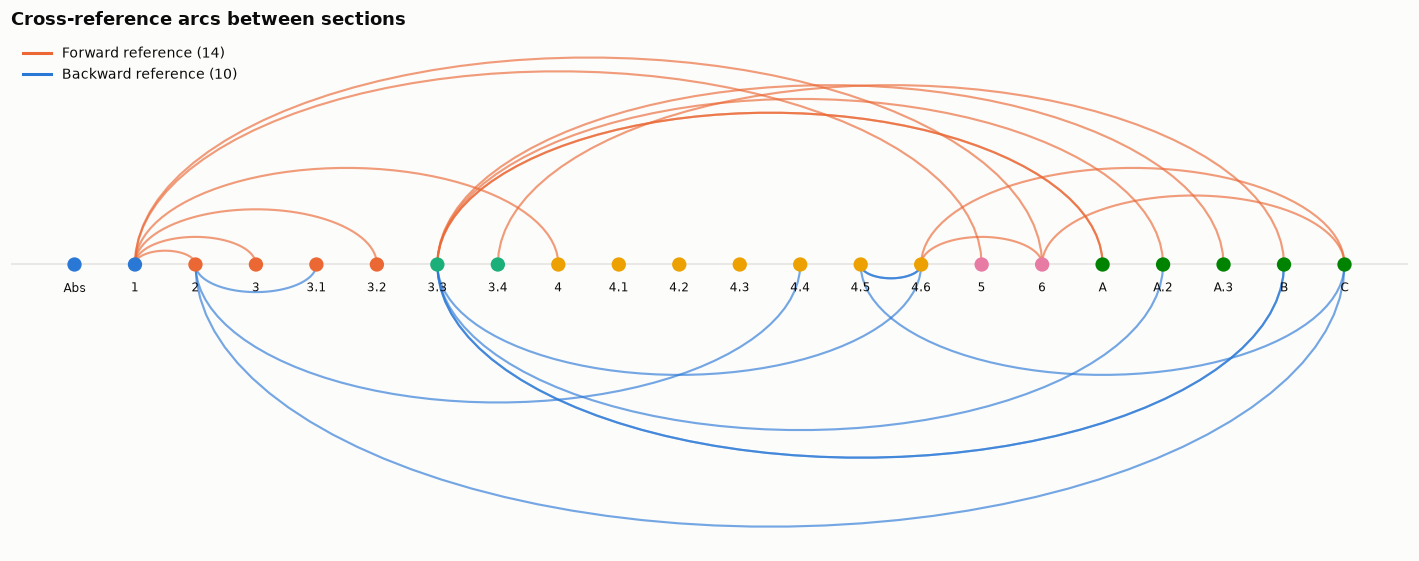

sid,1,3.1,3.3,3.4,4.4,4.6,6,A.2,B,C
forward,,,,,,,,,,
backward,0,1,0,0,1,3,0,1,2,2
forward,6,0,4,1,0,2,1,0,0,0


In [14]:
TARGET = {"Figure 1": "2", "Figure 2": "4.5", "Figure 3": "4.6", "Figure 4": "C", "Figure 5": "C",
          "Algorithm 1": "3.2", "Equation 3": "3.3", "Equation 5": "3.3", "Theorem 3.2": "3.3",
          "Theorem 3.4": "3.3", "Lemma 3.3": "3.3", "Lemma 3.5": "3.3", "Lemma 3.6": "3.3",
          "Proposition B.1": "B", "Proposition B.2": "B", "Table 1": "B"}
SEC_ORDER = {s: i for i, s in enumerate(S.index)}
refs = []
for _, r in sen.iterrows():
    t = r.text.replace("equation", "Equation")
    for m in re.finditer(r"Sections? (\d(?:\.\d)?)(?: and (\d))?", t):
        for g in m.groups():
            if g: refs.append((r.sid, g, "Section"))
    for m in re.finditer(r"Appendix ([A-C])(?:\.(\d))?", t):
        refs.append((r.sid, m.group(1) if m.group(1) != "A" or not m.group(2) or m.group(2) == "1" else f"A.{m.group(2)}", "Appendix"))
    for m in re.finditer(r"(Figure|Algorithm|Equation|Theorem|Lemma|Proposition|Table) (\d|[A-B]\.\d|\d\.\d)", t):
        key = f"{m.group(1)} {m.group(2)}"
        if key in TARGET: refs.append((r.sid, TARGET[key], m.group(1)))
R = pd.DataFrame(refs, columns=["src", "dst", "kind"])
R = R[R.src != R.dst].copy()
R["src_i"] = R.src.map(SEC_ORDER); R["dst_i"] = R.dst.map(SEC_ORDER)
R = R.dropna(); R["forward"] = R.dst_i > R.src_i

fig, ax = plt.subplots(figsize=(13, 5.2))
xs = np.arange(len(S))
for _, r in R.iterrows():
    a, b = r.src_i, r.dst_i
    h = abs(b - a) / 2
    th = np.linspace(0, np.pi, 50)
    sign = 1 if r.forward else -1
    ax.plot((a + b) / 2 + (b - a) / 2 * np.cos(th[::-1] if b > a else th), sign * h * np.sin(th) * .55,
            color=C["orange"] if r.forward else C["blue"], lw=1.4, alpha=.65)
ax.scatter(xs, np.zeros_like(xs), s=70, color=[ROLE_COLOR[r] for r in S.role], zorder=3)
for x, s in zip(xs, S.index):
    ax.text(x, -.35, s, ha="center", va="top", fontsize=8)
ax.axhline(0, color=C["grid"], lw=1)
ax.set_yticks([]); ax.set_xticks([]); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
ax.legend(handles=[plt.Line2D([], [], color=C["orange"], lw=2, label=f"Forward reference ({R.forward.sum()})"),
                   plt.Line2D([], [], color=C["blue"], lw=2, label=f"Backward reference ({(~R.forward).sum()})")],
          loc="upper left", fontsize=9)
ax.set_title("Cross-reference arcs between sections")
plt.tight_layout(); plt.show()
R.groupby(["src", "forward"]).size().unstack(fill_value=0).rename(columns={True: "forward", False: "backward"}).reindex(S.index).dropna().astype(int).T

**Findings.** The paper has **more forward references than backward ones**. Most come from three sources:
1. The Introduction's roadmap, which is expected.
2. Section 3.3 deferring proofs to Appendices A.1–A.3, which is standard.
3. Results sending readers to Appendix C.

The arc from 6 → C (recall values) is the right way to back a limitation with evidence. **One problem**: Figure 1 lives in Section 2 but illustrates the proof of Proposition 3.1 in Section 3.1. A reader meets it before they can understand it. Likewise, Figure 3 is typeset inside Related Work although it belongs to 4.6. Moving each figure next to its first reference would remove two "where is this?" detours.

### 2e. Concept introduction map: are ideas set up before they are used?

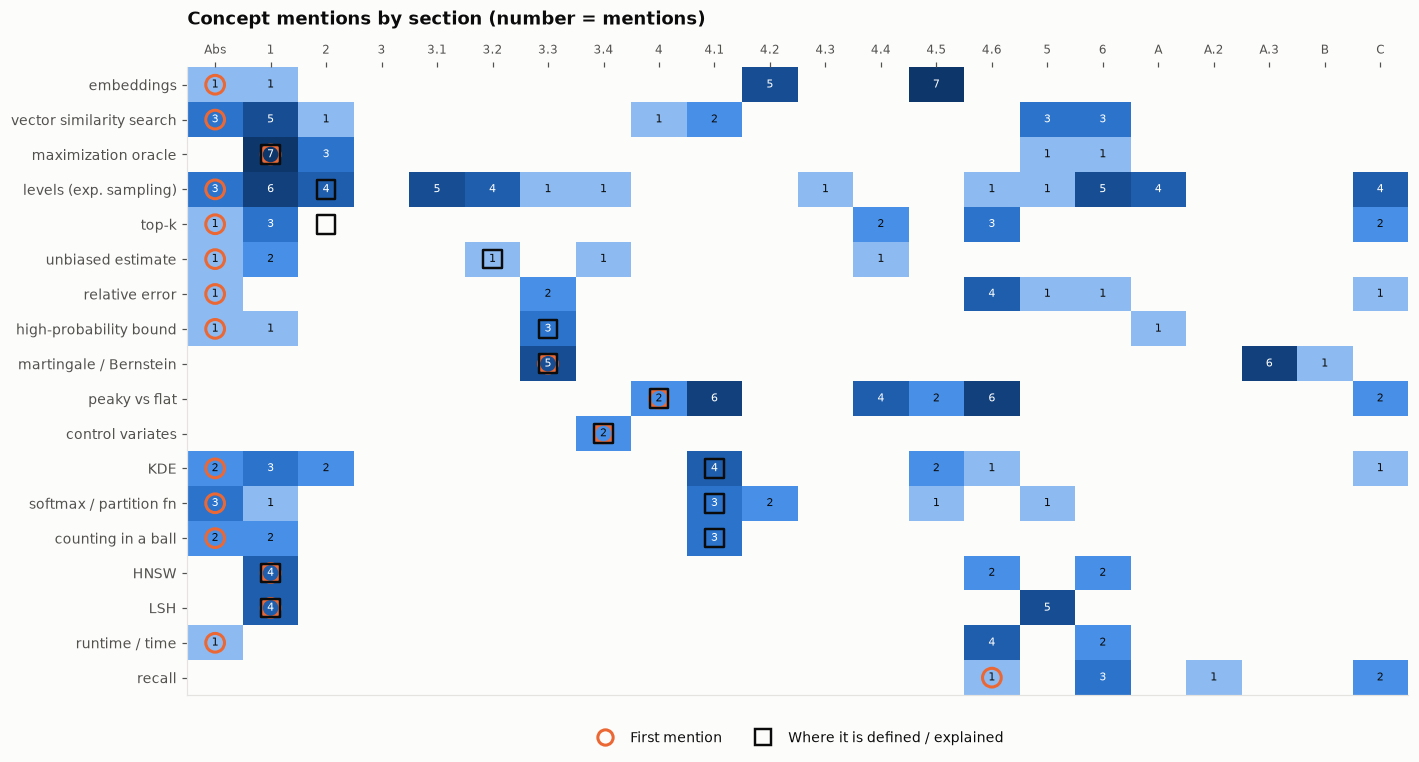

In [15]:
CONCEPTS = {
    "embeddings": r"embedding", "vector similarity search": r"vector similar(?:ity)? search",
    "maximization oracle": r"oracle", "levels (exp. sampling)": r"\blevels?\b",
    "top-k": r"top-?k", "unbiased estimate": r"unbiased", "relative error": r"relative error",
    "high-probability bound": r"high[- ]probability", "martingale / Bernstein": r"martingale|bernstein",
    "peaky vs flat": r"peaky|flat", "control variates": r"control variates|correction term",
    "KDE": r"\bKDE\b|kernel[- ]density", "softmax / partition fn": r"softmax|partition function|normaliz",
    "counting in a ball": r"\bcount(?:ing)?\b|within a (?:ball|radius)", "HNSW": r"HNSW", "LSH": r"\bLSH\b|locality",
    "runtime / time": r"runtime|computational time|computation time", "recall": r"\brecall\b",
}
DEFINED_IN = {"embeddings": None, "vector similarity search": None, "maximization oracle": "1",
              "levels (exp. sampling)": "2", "top-k": "2", "unbiased estimate": "3.2", "relative error": None,
              "high-probability bound": "3.3", "martingale / Bernstein": "3.3", "peaky vs flat": "4",
              "control variates": "3.4", "KDE": "4.1", "softmax / partition fn": "4.1",
              "counting in a ball": "4.1", "HNSW": "1", "LSH": "1", "runtime / time": None, "recall": None}
M = pd.DataFrame({c: sen.groupby("sid", sort=False).text.apply(lambda ts, p=p: sum(len(re.findall(p, t, re.I)) for t in ts))
                  for c, p in CONCEPTS.items()}).reindex(S.index).T
fig, ax = plt.subplots(figsize=(13, 7))
ax.imshow(np.log1p(M.values), cmap=seq_cmap, aspect="auto")
for i, c in enumerate(M.index):
    nz = np.nonzero(M.values[i])[0]
    if len(nz): ax.scatter(nz[0], i, marker="o", s=150, facecolors="none", edgecolors=C["orange"], lw=2, zorder=3)
    if DEFINED_IN.get(c) in M.columns:
        j = list(M.columns).index(DEFINED_IN[c])
        ax.scatter(j, i, marker="s", s=150, facecolors="none", edgecolors=C["ink"], lw=1.6, zorder=3)
    for j, v in enumerate(M.values[i]):
        if v: ax.text(j, i, int(v), ha="center", va="center", fontsize=7,
                      color="white" if np.log1p(v) > np.log1p(M.values.max()) * .55 else C["ink"])
ax.set_xticks(range(M.shape[1]), M.columns, fontsize=8); ax.set_yticks(range(M.shape[0]), M.index, fontsize=9)
ax.xaxis.tick_top(); ax.grid(False)
ax.legend(handles=[plt.Line2D([], [], marker="o", ls="", mfc="none", mec=C["orange"], mew=2, ms=10, label="First mention"),
                   plt.Line2D([], [], marker="s", ls="", mfc="none", mec=C["ink"], mew=1.6, ms=10, label="Where it is defined / explained")],
          loc="lower center", bbox_to_anchor=(.5, -.1), ncol=2, fontsize=9)
ax.set_title("Concept mentions by section (number = mentions)", pad=28)
plt.tight_layout(); plt.show()

**Findings on flow**
- **The skeleton is classic and sound**: problem → prior work's gap (O(√n)) → key idea (levels) → estimator → guarantee → experiments → limitations. Every contribution bullet has a matching section.
- **"Unbiased" and "high-probability bound" are promised in the Abstract and Introduction long before they are defined** (3.2, 3.3). That is normal, but a one-sentence intuition early ("each sampled value is up-weighted by the inverse of its chance of being seen") would let lay readers follow the promise.
- **Some definitions live only in notation.** *Top-k* is defined in Section 2 purely as ⟨m⟩ (the empty black square in the chart), and the first plain-words explanation comes in 4.4 Baselines. *Maximization oracle* is defined in prose in the Introduction, which is good, but it is a theory-of-computing term many ML readers will pause on.
- **"Peaky vs flat" is the paper's best intuition device, but it first appears in Section 4.** It explains *why* top-k fails in one regime and random sampling in the other, and why the new method is needed. Introduced in the Introduction, it would motivate the whole design, not just the experiments.
- **Runtime is claimed in the Abstract ("less computational time") but the theory says nothing about runtime** (Section 6 says so explicitly). The claim is supported only by Figure 3, and one panel shows a tie. The argument flows, but the Abstract slightly over-reaches relative to the evidence (see 5b).
- **There is no Conclusion section.** The paper ends on a forward-looking HNSW paragraph, so the reader never gets a closing restatement of what was shown.

---
# Q3. Tone and pacing

### 3a. Tone: hedging versus confident language
Hedges soften a claim (*perhaps, likely, approximately, typically, may*). Boosters strengthen it (*prove, provably, novel, significantly, always, simple, key*). Both are counted per 100 words.

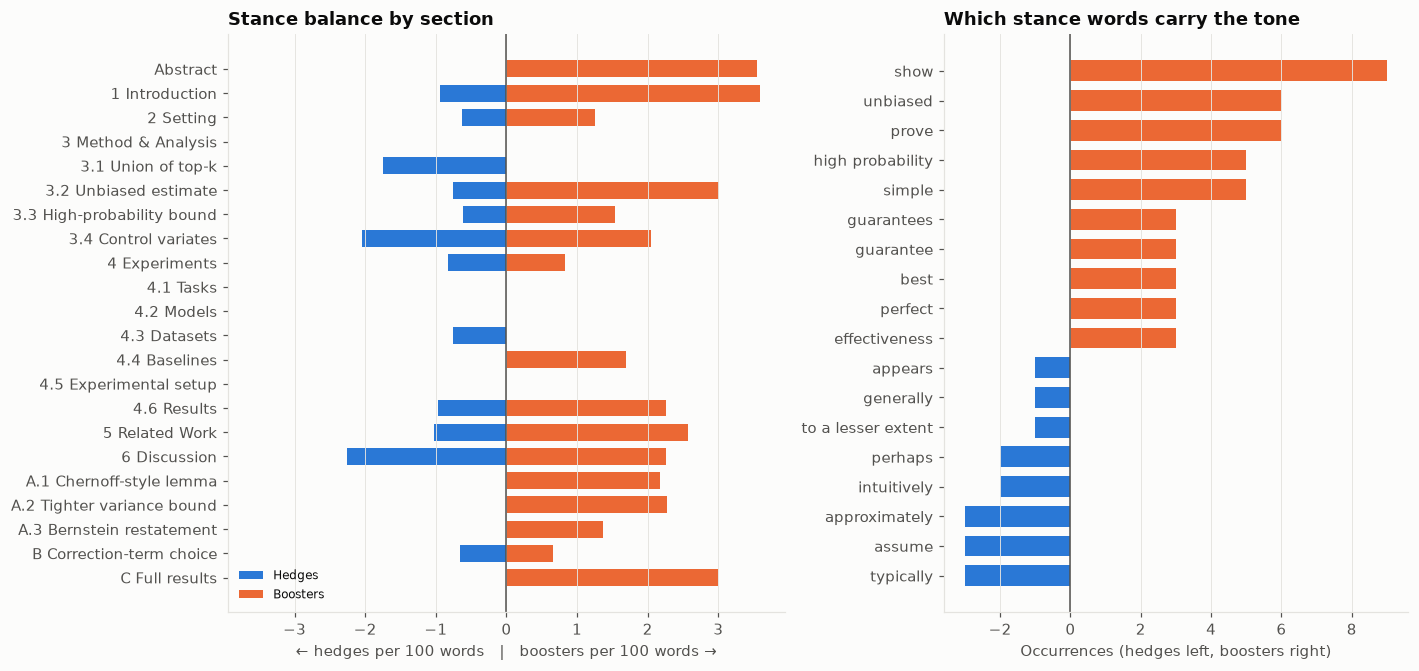

Whole paper: 0.68 hedges and 1.82 boosters per 100 words


In [16]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw=dict(width_ratios=[1.2, 1]))
y = np.arange(len(S))[::-1]
a1.barh(y, -S.hedges, color=C["blue"], height=.7, label="Hedges")
a1.barh(y, S.boosters, color=C["orange"], height=.7, label="Boosters")
a1.axvline(0, color=C["ink2"], lw=1)
a1.set_yticks(y, S.label_short); a1.set_xlabel("← hedges per 100 words   |   boosters per 100 words →")
a1.set_title("Stance balance by section"); a1.legend(loc="lower left", fontsize=8); a1.grid(axis="y", visible=False)
lim = max(S.hedges.max(), S.boosters.max()) * 1.1; a1.set_xlim(-lim, lim)

hb = Counter(); bb = Counter()
for s in sen.text_nocite:
    hb.update(L.term_hits(s, L.HEDGES)); bb.update(L.term_hits(s, L.BOOSTERS))
items = [(k, -v, C["blue"]) for k, v in hb.most_common(8)] + [(k, v, C["orange"]) for k, v in bb.most_common(10)]
items.sort(key=lambda t: t[1])
a2.barh([k for k, _, _ in items], [v for _, v, _ in items], color=[c for _, _, c in items], height=.7)
a2.axvline(0, color=C["ink2"], lw=1); a2.set_xlabel("Occurrences (hedges left, boosters right)")
a2.set_title("Which stance words carry the tone"); a2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()
print(f"Whole paper: {100*sen.hedges.sum()/sen.words.sum():.2f} hedges and {100*sen.boosters.sum()/sen.words.sum():.2f} boosters per 100 words")

**Findings on tone**
- **The tone is confident, measured and understated.** Boosters outnumber hedges about 2.7 to 1 (1.8 against 0.7 per 100 words). But the top boosters are *technical*, not promotional. *Show* (9), *unbiased* (6), *prove* (6) and *high probability* (5) are claims of the method's actual properties, not adjectives. The two promotional words, *novel* (Abstract) and *significantly* (Section 6), appear once each.
- **The Abstract and Introduction are the most assertive parts** (about 3.5 boosters per 100 words). That fits their job, but it puts the strongest language exactly where the evidence hasn't been shown yet (see 5b).
- ***Simple* is the paper's favourite self-description** (5 uses: "a simple algorithm", "simple estimate", "the simple algorithm", "simple way", "simple form"). It sets a friendly, unpretentious tone. But it is also a mild booster that can backfire when the very next paragraph is a martingale argument. Keep it for Algorithm 1, where it is earned.
- **Hedging is concentrated where it should be**: the Discussion (the most hedged section: "typically approximate", "it is likely that a slightly modified HNSW…", "assumes perfect recall"), 3.4 Control variates ("imperfect", "typically") and Related Work ("perhaps the only class"). The authors are candid about the oracle assumption and the missing runtime guarantee. That honesty builds credibility.
- The **voice is collegial "we"**, with occasional conversational touches ("perhaps surprisingly", "too quickly", "we're done", "best of both worlds", "don't"). They make the proofs feel walked-through rather than recited, though the contractions are slightly informal for a venue paper.

### 3b. Pacing: how fast does the paper move?

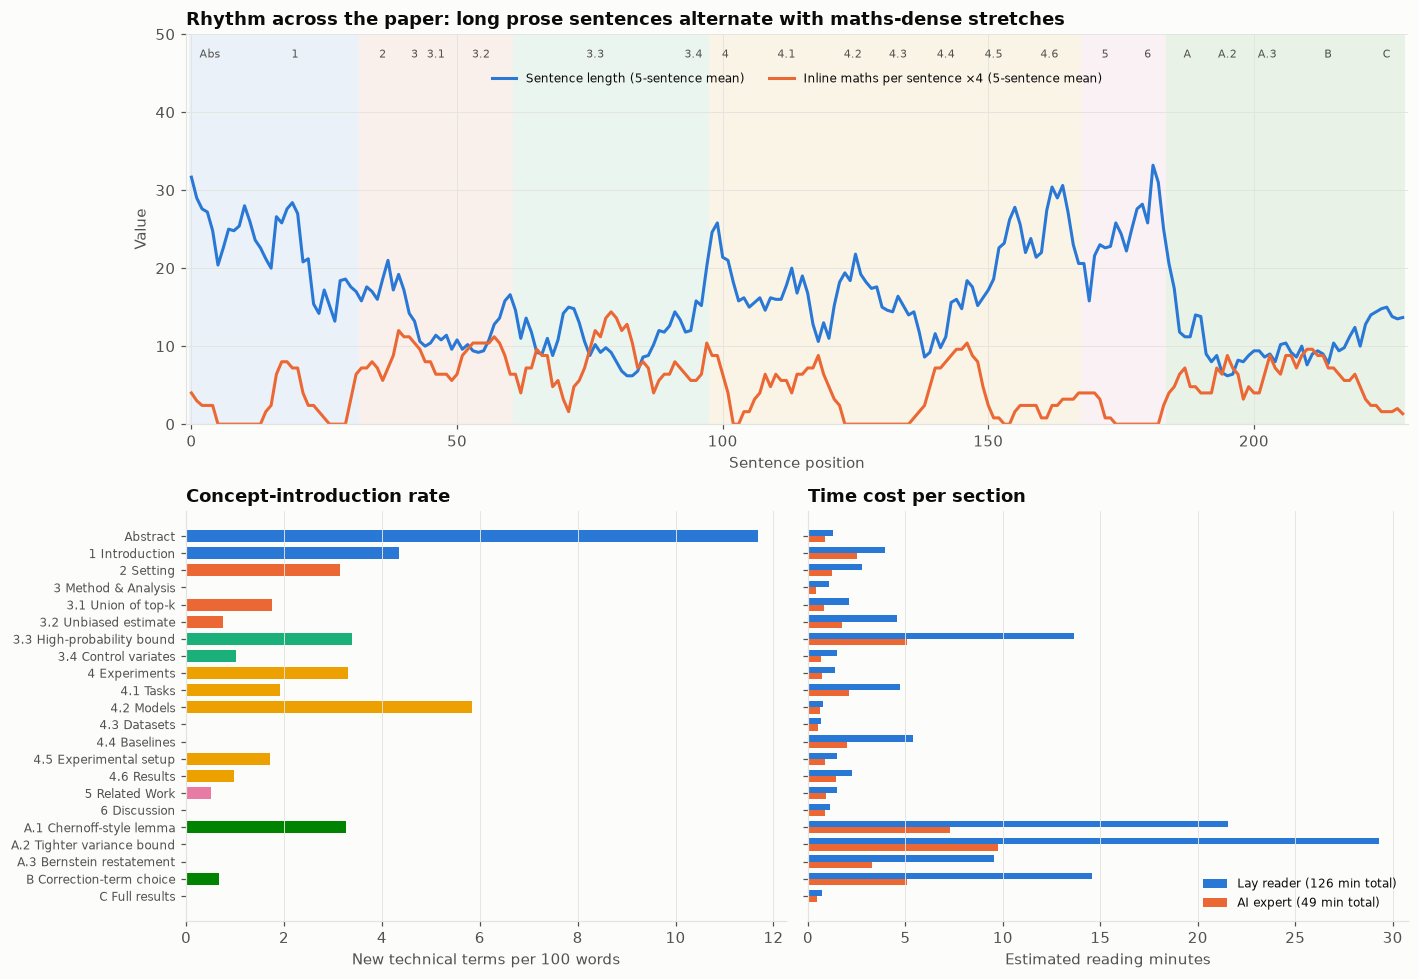

In [17]:
# New technical concepts per 100 words: first occurrence of each concept/acronym/jargon term.
vocab = list(CONCEPTS.items()) + [(t, re.escape(t)) for t in L.ML_JARGON + L.THEORY_JARGON]
seen, new_terms = set(), []
for _, r in sen.iterrows():
    n = 0
    for name, pat in vocab:
        if name not in seen and re.search(pat, r.text, re.I):
            seen.add(name); n += 1
    new_terms.append(n)
sen["new_terms"] = new_terms
S["new_per100"] = sen.groupby("sid", sort=False).new_terms.sum().reindex(S.index) / S.words * 100

# Reading-time model (assumptions stated in the markdown below).
S["lay_min"] = S.words / 200 + S.equations * 1.0 + S.inline_math * S.words / 100 * 0.10
S["exp_min"] = S.words / 250 + S.equations * 0.33 + S.inline_math * S.words / 100 * 0.03

fig = plt.figure(figsize=(13, 9))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.05])
a1 = fig.add_subplot(gs[0, :])
for sid, g in sen.groupby("sid", sort=False):
    a1.axvspan(g.pos.min() - .5, g.pos.max() + .5, color=ROLE_COLOR[g.role.iloc[0]], alpha=.08, lw=0)
    a1.text((g.pos.min() + g.pos.max()) / 2, 47, sid, ha="center", fontsize=7, color=C["ink2"])
a1.plot(sen.pos, sen.words.rolling(5, center=True, min_periods=2).mean(), color=C["blue"], label="Sentence length (5-sentence mean)")
a1.plot(sen.pos, (sen.inline_math + 0).rolling(5, center=True, min_periods=2).mean() * 4, color=C["orange"],
        label="Inline maths per sentence ×4 (5-sentence mean)")
a1.set_ylim(0, 50); a1.set_xlim(-1, len(sen)); a1.set_xlabel("Sentence position"); a1.set_ylabel("Value")
a1.set_title("Rhythm across the paper: long prose sentences alternate with maths-dense stretches")
a1.legend(loc="upper center", ncol=2, fontsize=8, bbox_to_anchor=(.5, .93))

a2 = fig.add_subplot(gs[1, 0])
y = np.arange(len(S))[::-1]
a2.barh(y, S.new_per100, color=[ROLE_COLOR[r] for r in S.role], height=.7)
a2.set_yticks(y, S.label_short, fontsize=8); a2.set_xlabel("New technical terms per 100 words")
a2.set_title("Concept-introduction rate"); a2.grid(axis="y", visible=False)

a3 = fig.add_subplot(gs[1, 1], sharey=a2)
a3.barh(y + .18, S.lay_min, height=.36, color=C["blue"], label=f"Lay reader ({S.lay_min.sum():.0f} min total)")
a3.barh(y - .18, S.exp_min, height=.36, color=C["orange"], label=f"AI expert ({S.exp_min.sum():.0f} min total)")
a3.set_xlabel("Estimated reading minutes"); a3.set_title("Time cost per section")
a3.legend(loc="lower right", fontsize=8); a3.grid(axis="y", visible=False)
plt.setp(a3.get_yticklabels(), visible=False)
plt.tight_layout(); plt.show()

*Reading-time model:* a lay reader reads at 200 wpm, spends about 1 min per display equation and about 6 s per inline expression. An expert reads at 250 wpm, spends about 20 s per equation and about 2 s per inline expression. These are rough, but the ratios between sections are what matter.

**Findings on pacing**
- **The pacing is front-loaded with concepts.** The Abstract introduces about 12 new technical terms per 100 words, roughly 3× the Introduction and higher than anywhere else. Embeddings, vector similarity search, KDE, softmax, top-k, levels, unbiasedness and relative-error bounds all arrive in 197 words. That is a steep on-ramp for a non-specialist. 4.2 Models is the second spike (CLIP, ViT, DistilBERT, BERT, knowledge distillation), but those terms are incidental to the argument.
- **The method itself (Sections 2–3.2) is very fast.** The core algorithm takes about 380 words, plus Algorithm 1. For experts this is admirable concision. For everyone else it is the moment the paper speeds up without warning: the orange maths line in the rhythm chart jumps the moment Section 2 begins.
- **Section 3.3 is the slow, heavy stretch.** It takes over a quarter of a lay reader's main-text time for a result the Abstract summarises in one clause. Experts move through it in about 5 minutes, because the proof pattern (Chernoff → union bound → Bernstein) is familiar.
- **The experiments decelerate nicely.** Sections 4.1–4.5 use short sentences with one idea per paragraph. Section 4.6 picks the pace back up with long comparative sentences, the right move for a results section.
- **The ending is abrupt.** Section 6 has the paper's longest average sentence (26 words) and stops without a summary. The reader exits mid-thought (see the recommendation to add a Conclusion).
- **Overall cost:** about 50 minutes for a lay reader to get through the main text closely (about 125 minutes including the appendix), against about 23 minutes (about 50 with the appendix) for an expert.

---
# Q4. Audience density: lay readers versus AI experts

### 4a. Two density indices
Each section is scored on eight components. Each component is min–max normalised across sections, and the weighted sum is rescaled so that, for each audience, the lightest section scores 0 and the densest scores 100. The weights differ by audience:

| Component | Lay-reader weight | AI-expert weight | Why |
|---|---|---|---|
| Inline maths per 100 words | 0.25 | 0.25 | Notation is the biggest single barrier for a lay reader, and still costly for experts |
| Display equations per 100 words (log) | 0.20 | 0.25 | |
| Probability/theory vocabulary | 0.15 | 0.25 | Many ML practitioners don't use martingales daily |
| Flesch–Kincaid grade | 0.10 | 0.05 | Long sentences slow everyone, but experts less so |
| Dale–Chall "difficult" words % | 0.10 | 0.00 | Experts know academic vocabulary |
| AI/ML vocabulary | 0.10 | 0.00 | *Embedding, softmax, HNSW* are everyday words for experts |
| Acronyms per 100 words | 0.05 | 0.00 | |
| New-concept rate | 0.05 | 0.20 | Experts are slowed by *new ideas*, not by vocabulary |

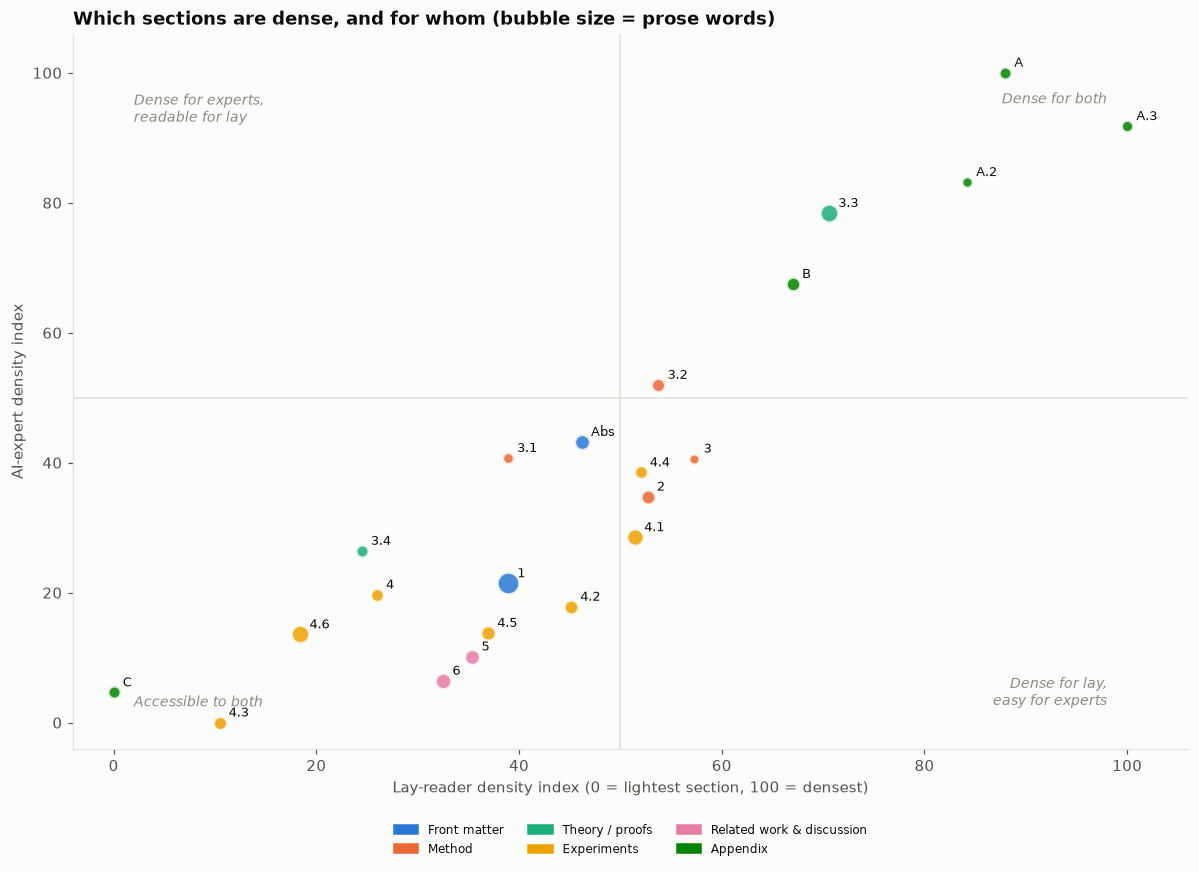

In [18]:
def norm01(s): return (s - s.min()) / (s.max() - s.min())
comp = pd.DataFrame({
    "FK grade": norm01(S.fk_grade), "Difficult words": norm01(S.difficult_pct),
    "AI/ML vocab": norm01(S.ml_jargon), "Theory vocab": norm01(S.theory_jargon),
    "Inline maths": norm01(S.inline_math), "Equations": norm01(np.log1p(S.eq_per100)),
    "Acronyms": norm01(S.acronyms), "New concepts": norm01(S.new_per100)})
W_LAY = {"FK grade": .10, "Difficult words": .10, "AI/ML vocab": .10, "Theory vocab": .15,
         "Inline maths": .25, "Equations": .20, "Acronyms": .05, "New concepts": .05}
W_EXP = {"FK grade": .05, "Difficult words": 0, "AI/ML vocab": 0, "Theory vocab": .25,
         "Inline maths": .25, "Equations": .25, "Acronyms": 0, "New concepts": .20}
lay_raw = sum(comp[k] * w for k, w in W_LAY.items())
exp_raw = sum(comp[k] * w for k, w in W_EXP.items())
S["lay_density"] = 100 * norm01(lay_raw)
S["exp_density"] = 100 * norm01(exp_raw)

fig, ax = plt.subplots(figsize=(11, 8))
ax.axvline(50, color=C["grid"], lw=1.2); ax.axhline(50, color=C["grid"], lw=1.2)
for (x0, y0, txt) in [(2, 97, "Dense for experts,\nreadable for lay"), (98, 97, "Dense for both"),
                      (2, 2, "Accessible to both"), (98, 2, "Dense for lay,\neasy for experts")]:
    ax.text(x0, y0, txt, ha="left" if x0 < 50 else "right", va="top" if y0 > 50 else "bottom",
            fontsize=9, color=C["muted"], style="italic")
for r in S.itertuples():
    ax.scatter(r.lay_density, r.exp_density, s=40 + r.words / 3, color=ROLE_COLOR[r.role],
               alpha=.85, edgecolor=C["surface"], lw=2, zorder=3)
    ax.annotate(r.Index, (r.lay_density, r.exp_density), xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.set_xlim(-4, 106); ax.set_ylim(-4, 106)
ax.set_xlabel("Lay-reader density index (0 = lightest section, 100 = densest)")
ax.set_ylabel("AI-expert density index")
ax.set_title("Which sections are dense, and for whom (bubble size = prose words)")
role_legend(ax, loc="upper center", bbox_to_anchor=(.5, -.09), ncol=3, fontsize=8)
ax.grid(False)
plt.tight_layout(); plt.show()

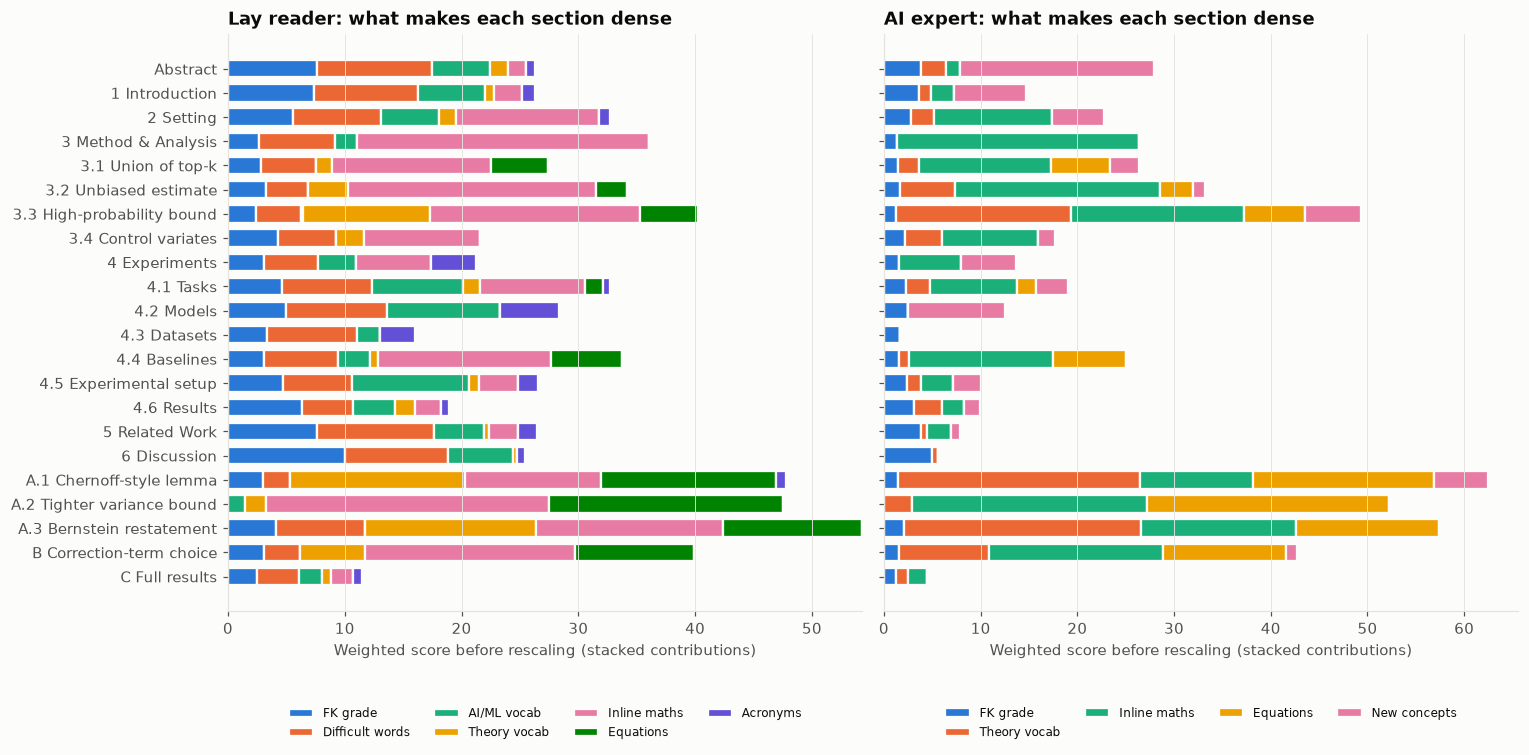

,label_short,lay_density,exp_density,lay_min,exp_min
sid,,,,,
A.3,A.3 Bernstein restatement,100.0,91.8,9.6,3.3
A,A.1 Chernoff-style lemma,88.0,100.0,21.6,7.3
A.2,A.2 Tighter variance bound,84.2,83.2,29.3,9.7
3.3,3.3 High-probability bound,70.6,78.4,13.6,5.1
B,B Correction-term choice,67.0,67.5,14.6,5.1
3,3 Method & Analysis,57.3,40.6,1.1,0.4
3.2,3.2 Unbiased estimate,53.7,52.0,4.6,1.7
2,2 Setting,52.7,34.8,2.8,1.2
4.4,4.4 Baselines,52.0,38.5,5.4,2.0


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, wts, title, col in [(axes[0], W_LAY, "Lay reader: what makes each section dense", C["blue"]),
                            (axes[1], W_EXP, "AI expert: what makes each section dense", C["orange"])]:
    keys = [k for k, w in wts.items() if w]
    contrib = pd.DataFrame({k: comp[k] * wts[k] * 100 for k in keys})
    y = np.arange(len(S))[::-1]
    left = np.zeros(len(S))
    pal = [C["blue"], C["orange"], C["aqua"], C["yellow"], C["magenta"], C["green"], C["violet"]]
    for k, c in zip(keys, pal):
        ax.barh(y, contrib[k], left=left, color=c, height=.72, label=k, edgecolor=C["surface"], linewidth=1.5)
        left += contrib[k].values
    ax.set_title(title); ax.set_xlabel("Weighted score before rescaling (stacked contributions)"); ax.grid(axis="y", visible=False)
    ax.legend(loc="lower center", bbox_to_anchor=(.5, -.24), ncol=4, fontsize=8)
axes[0].set_yticks(np.arange(len(S))[::-1], S.label_short)
plt.tight_layout(); plt.show()
S[["label_short", "lay_density", "exp_density", "lay_min", "exp_min"]].round(1).sort_values("lay_density", ascending=False)

**Findings on density**

*For a lay reader*
- **Densest:** the appendix (A.3, A.1, A.2, B), then **3.3 High-probability bound**, then the method block (**3, 3.2, 2**). Notation and theory vocabulary pile up there. **Section 2 is the real cliff.** It is the *first* place maths takes over (from 2.5 to 12.6 inline expressions per 100 words) and it comes straight after a readable Introduction.
- **Dense without maths:** **4.4 Baselines, 4.1 Tasks, the Abstract and 4.2 Models** sit in the middle of the lay scale for different reasons. 4.1 and 4.4 embed formulas; the Abstract has the highest new-concept rate; 4.2 is wall-to-wall model names. The Abstract's maths symbols (O(√n), O(log n)) are few, but they are the punchline, and a lay reader can't decode them.
- **Most accessible:** **Appendix C, 4.3 Datasets, 4.6 Results, 3.4 (short), Section 4's intro and 6 Discussion.** Concrete nouns (Amazon reviews, images, AWS machines) and plain claims ("our method achieves lower error for the same runtime").

*For an AI expert*
- **Densest:** the appendix proofs (A.1, A.3, A.2) and **3.3**, then **B** and **3.2**. The difficulty is conceptual (martingale concentration, inverse-probability weighting), not linguistic. **3.2 Unbiased estimate** is dense *per word*: the whole estimator is packed into about 130 words.
- **Light:** 4.3, Appendix C, the Discussion, Related Work, 4.5 and 4.6. These are familiar territory for an ML researcher, who can move quickly.
- **Biggest audience gap** (lay ≫ expert): **4.2 Models, 6 Discussion, 5 Related Work, 4.5 Setup and 4.1 Tasks.** Vocabulary that is jargon to one reader (CLIP, softmax, HNSW, LSH) is everyday language to the other, and long sentences cost a lay reader more.
- **No section is "dense for experts but easy for lay readers"** (the empty top-left quadrant). Everything hard for an expert is harder still for a lay reader, as you'd expect from a paper whose difficulty is mathematical.

### 4b. Recommended reading order for each audience
The paper is cut into 15 reading units; the Introduction is split into its motivation half and its idea/contributions half. Each unit gets a **value** for each audience:
- a lay reader wants what problem this solves, whether it works, and what its limits are;
- an expert wants what is new, how it works, why it is correct, and how it compares.

The **depth** (read closely / skim / optional) is computed from value and density: units with value ≥ 0.7 are read closely, and units with value ≥ 0.4, or with low density for that audience, are skimmed. The **order** is editorial. It follows each audience's natural sequence of questions and respects prerequisites (for example, Results come after Tasks and Baselines). Bar length is the time cost at that depth, and the label is the unit's density index for that audience.

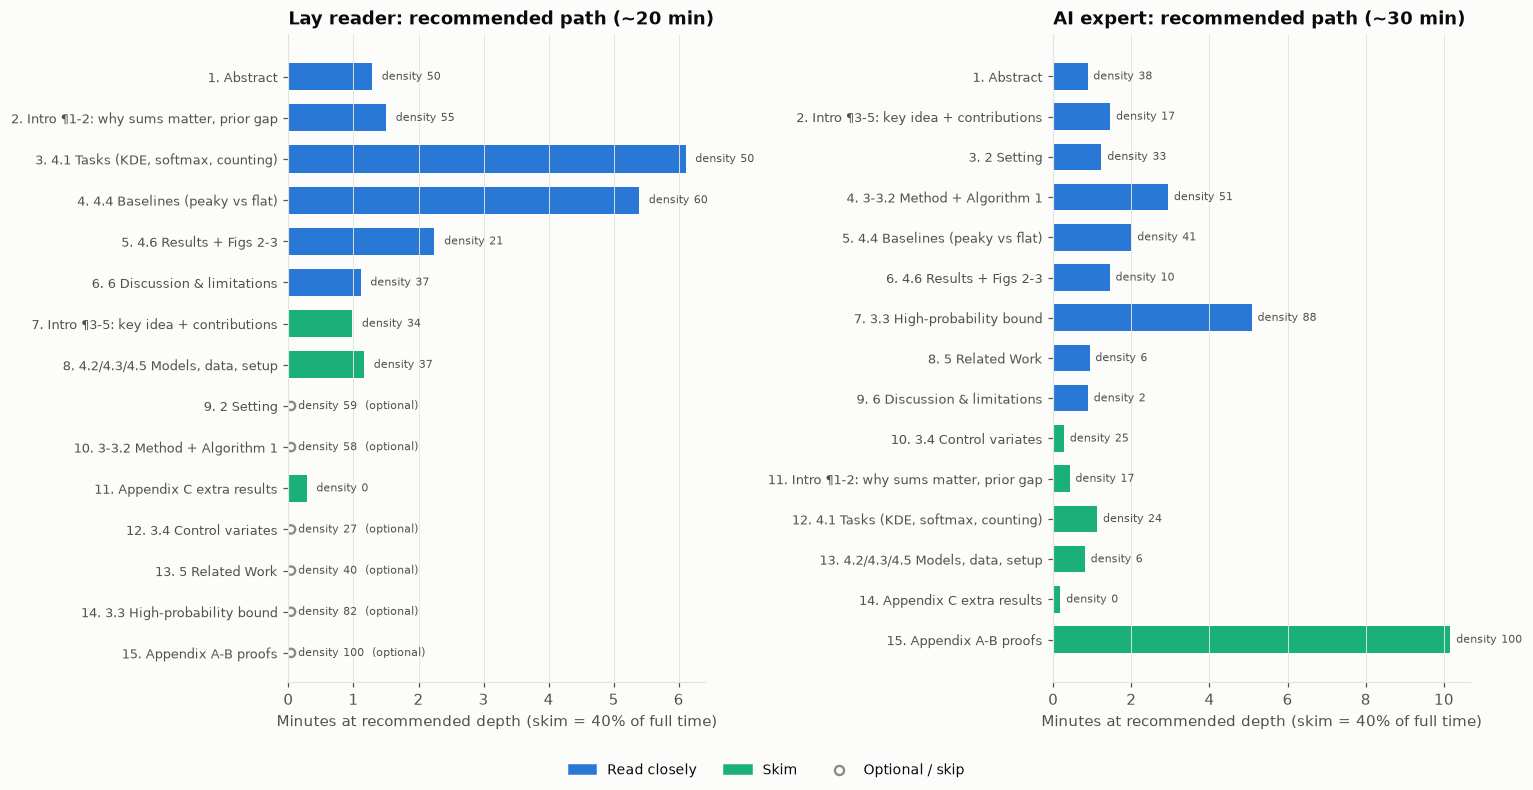

In [20]:
UNITS = [  # id, label, sections (or intro paragraphs), lay value, expert value, prerequisites
    ("Abs", "Abstract", ["Abs"], 1.0, 1.0, []),
    ("1a", "Intro ¶1-2: why sums matter, prior gap", ["1a"], .9, .5, ["Abs"]),
    ("1b", "Intro ¶3-5: key idea + contributions", ["1b"], .6, 1.0, ["Abs"]),
    ("2", "2 Setting", ["2"], .3, .9, ["1b"]),
    ("3", "3-3.2 Method + Algorithm 1", ["3", "3.1", "3.2"], .35, 1.0, ["2"]),
    ("3.3", "3.3 High-probability bound", ["3.3"], .1, .8, ["3"]),
    ("3.4", "3.4 Control variates", ["3.4"], .1, .55, ["3"]),
    ("4.1", "4.1 Tasks (KDE, softmax, counting)", ["4", "4.1"], .7, .45, ["1a"]),
    ("4.4", "4.4 Baselines (peaky vs flat)", ["4.4"], .75, .7, ["Abs"]),
    ("4.x", "4.2/4.3/4.5 Models, data, setup", ["4.2", "4.3", "4.5"], .45, .45, ["4.1"]),
    ("4.6", "4.6 Results + Figs 2-3", ["4.6"], .95, 1.0, ["4.4"]),
    ("5", "5 Related Work", ["5"], .15, .8, ["1b"]),
    ("6", "6 Discussion & limitations", ["6"], .8, .9, ["4.6"]),
    ("App", "Appendix A-B proofs", ["A", "A.2", "A.3", "B"], 0.0, .45, ["3.3"]),
    ("C", "Appendix C extra results", ["C"], .2, .55, ["4.6"]),
]
# Split the introduction by paragraph: first two paragraphs vs the rest.
intro_paras = sorted(sen[sen.sid == "1"].para.unique())
sen["unit_sid"] = sen.sid
sen.loc[(sen.sid == "1") & sen.para.isin(intro_paras[:2]), "unit_sid"] = "1a"
sen.loc[(sen.sid == "1") & ~sen.para.isin(intro_paras[:2]), "unit_sid"] = "1b"

eq_by = sec.set_index("sid").equations.to_dict()
U = []
for uid, label, sids, lv, ev, pre in UNITS:
    g = sen[sen.unit_sid.isin(sids)]
    m = metrics(g, sum(eq_by.get(s, 0) for s in sids))
    m["new_per100"] = 100 * g.new_terms.sum() / m.words
    U.append(dict(uid=uid, label=label, lay_value=lv, exp_value=ev, pre=pre, **m.to_dict()))
U = pd.DataFrame(U).set_index("uid")
uc = pd.DataFrame({"FK grade": norm01(U.fk_grade), "Difficult words": norm01(U.difficult_pct),
                   "AI/ML vocab": norm01(U.ml_jargon), "Theory vocab": norm01(U.theory_jargon),
                   "Inline maths": norm01(U.inline_math), "Equations": norm01(np.log1p(U.eq_per100)),
                   "Acronyms": norm01(U.acronyms), "New concepts": norm01(U.new_per100)})
U["lay_d"] = norm01(sum(uc[k] * w for k, w in W_LAY.items()))
U["exp_d"] = norm01(sum(uc[k] * w for k, w in W_EXP.items()))
U["lay_min"] = U.words / 200 + U.equations * 1.0 + U.inline_math * U.words / 100 * .10
U["exp_min"] = U.words / 250 + U.equations * .33 + U.inline_math * U.words / 100 * .03

LAY_ORDER = ["Abs", "1a", "4.1", "4.4", "4.6", "6", "1b", "4.x", "2", "3", "C", "3.4", "5", "3.3", "App"]
EXP_ORDER = ["Abs", "1b", "2", "3", "4.4", "4.6", "3.3", "5", "6", "3.4", "1a", "4.1", "4.x", "C", "App"]

def reading_path(order, value_col, dens_col):
    done, path = set(), []
    for u in order:
        assert all(p in done for p in U.loc[u, "pre"]), f"{u} placed before a prerequisite"
        v, d = U.loc[u, value_col], U.loc[u, dens_col]
        mode = "Read closely" if v >= .7 else ("Skim" if v >= .4 or d < .25 else "Optional / skip")
        path.append((u, mode)); done.add(u)
    return path

lay_path = reading_path(LAY_ORDER, "lay_value", "lay_d")
exp_path = reading_path(EXP_ORDER, "exp_value", "exp_d")

MODE_C = {"Read closely": C["blue"], "Skim": C["aqua"], "Optional / skip": C["muted"]}
DEPTH = {"Read closely": 1.0, "Skim": .4, "Optional / skip": 0.0}
fig, axes = plt.subplots(1, 2, figsize=(14, 7.2))
for ax, path, mins, dens, title in [(axes[0], lay_path, "lay_min", "lay_d", "Lay reader"),
                                    (axes[1], exp_path, "exp_min", "exp_d", "AI expert")]:
    y = np.arange(len(path))[::-1]
    for yi, (u, mode) in zip(y, path):
        t = U.loc[u, mins] * DEPTH[mode]
        if t:
            ax.barh(yi, t, color=MODE_C[mode], height=.66)
        else:
            ax.scatter(.04, yi, marker="o", s=30, facecolors="none", edgecolors=C["muted"], lw=1.5)
        ax.text(t + .15, yi, f"density {U.loc[u, dens] * 100:.0f}" + ("  (optional)" if not t else ""),
                va="center", fontsize=7.5, color=C["ink2"])
    ax.set_yticks(y, [f"{i + 1}. {U.loc[u, 'label']}" for i, (u, _) in enumerate(path)], fontsize=8.5)
    tot = sum(U.loc[u, mins] * DEPTH[m] for u, m in path)
    ax.set_title(f"{title}: recommended path (~{tot:.0f} min)")
    ax.set_xlabel("Minutes at recommended depth (skim = 40% of full time)")
    ax.grid(axis="y", visible=False)
fig.legend(handles=[Patch(color=MODE_C["Read closely"], label="Read closely"), Patch(color=MODE_C["Skim"], label="Skim"),
                    plt.Line2D([], [], marker="o", ls="", mfc="none", mec=C["muted"], mew=1.5, label="Optional / skip")],
           loc="lower center", ncol=3, fontsize=9)
plt.tight_layout(rect=(0, .05, 1, 1)); plt.show()

**Recommended reading orders**

**Lay reader (curious non-specialist, about 20 min)**
1. **Abstract.** Read for the problem only: "estimate a sum over everything using a search engine for similar items".
2. **Introduction ¶1–2.** Why embeddings and similarity search are everywhere, and why existing tricks need √n lookups.
3. **4.1 Tasks.** The three concrete uses (density, softmax, counting). This is where the problem becomes tangible. Skip past the formulas; the words around them carry the meaning.
4. **4.4 Baselines.** "Only the top items" versus "a random sample", plus the *peaky/flat* intuition. **This is the best plain-language explanation of the problem in the paper; read it before the method.**
5. **4.6 Results + Figures 2–3.** Does it work? Yes, mostly, at lower error for equal runtime.
6. **6 Discussion.** Honest limitations and the HNSW opportunity.
7. *Skim* Introduction ¶3–5 (the key idea of "levels") and 4.2/4.3/4.5 (what data and models were used).
8. *Optional:* Sections 2–3.2 for the flavour of the algorithm, and Appendix C. *Skip* 3.3, 3.4, Related Work and the proofs.

**AI expert (ML researcher or engineer, about 30 min)**
1. **Abstract → Introduction ¶3–5 (key idea + contributions).** The O(log n) against O(√n) claim and the skip-list/HNSW-style levels.
2. **Section 2 → 3–3.2 + Algorithm 1.** The whole method. Read slowly; it is short but dense.
3. **4.4 Baselines → 4.6 Results (Figures 2–3).** Check the error/runtime trade-off and the one tie (3b).
4. **3.3 Theorem 3.2 statement and the worked example** (n = 10⁷, k = 200 → error < 0.16). Theorists continue into the proof and Appendices A–B. Practitioners can stop at the statement.
5. **5 Related Work → 6 Discussion.** Position against Mussmann et al. 2017, Karppa et al. 2022 and the LSH-based estimators, plus the limits of the oracle assumption.
6. *Skim* Introduction ¶1–2, 4.1, 4.2/4.3/4.5 and 3.4. *Optional:* Appendix C (recall by level supports the perfect-recall assumption).

The key difference: **lay readers should reach the *results* and the *peaky/flat intuition* before the method; experts should reach the *method* before the results.** The paper's own order (Intro → Setting → Method → Theory → Experiments) is built for the expert path. That is right for a cs.DS preprint, but it means a lay reader has to jump to Section 4 to find their footing.

---
# 5. Other questions worth answering
### 5a. Terminology consistency

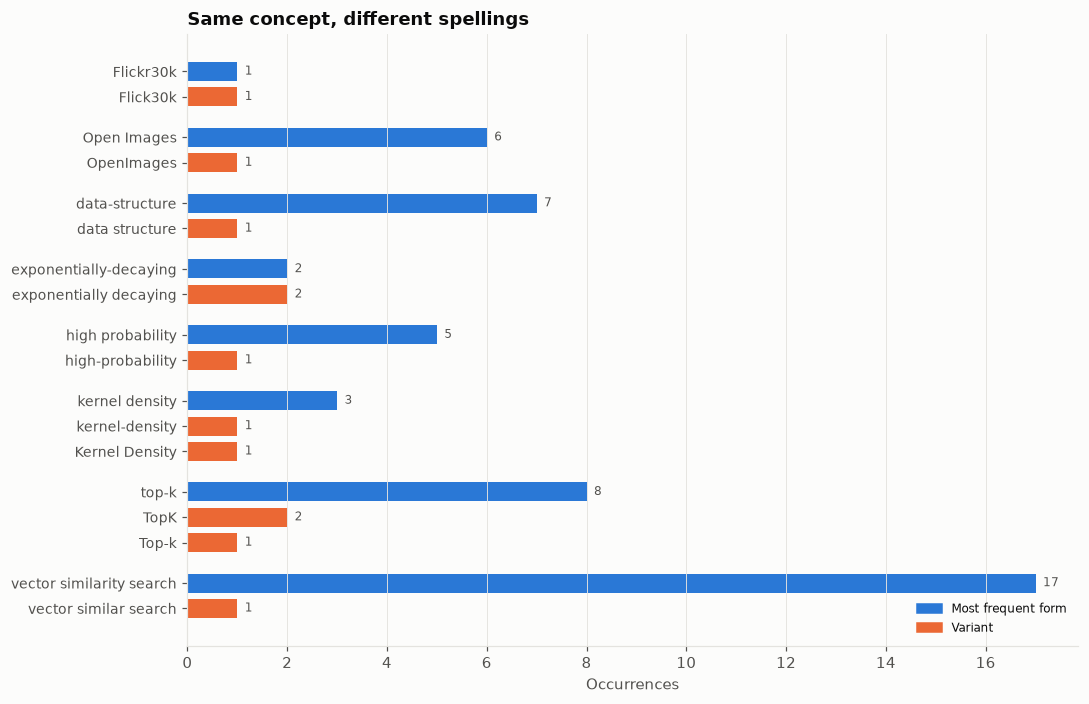

In [21]:
VARIANTS = {
    "Open Images": [r"Open Images", r"OpenImages"],
    "top-k": [r"\btop-k\b", r"\bTop-k\b", r"\bTopK\b"],
    "data structure": [r"data structure", r"data-structure"],
    "Flickr30k": [r"Flickr30k", r"Flick30k"],
    "vector similarity search": [r"vector similarity search", r"vector similar search"],
    "kernel density": [r"kernel density", r"kernel-density", r"Kernel Density"],
    "exp. decaying": [r"exponentially-decaying", r"exponentially decaying"],
    "high probability": [r"high probability", r"high-probability"],
    "log-linear": [r"log-linear", r"loglinear"],
}
rows = []
for concept, forms in VARIANTS.items():
    for f in forms:
        n = len(re.findall(f, " ".join(sen.text)))
        if n: rows.append((concept, f.replace(r"\b", ""), n))
V = pd.DataFrame(rows, columns=["concept", "form", "n"])
V = V[V.concept.isin(V.groupby("concept").form.nunique().loc[lambda s: s > 1].index)]
V = V.sort_values(["concept", "n"], ascending=[True, False])
V["dominant"] = ~V.duplicated("concept")
ypos, labels, y = [], [], 0
for cpt, sub in V.groupby("concept", sort=False):
    for _, r in sub.iterrows():
        ypos.append(y); labels.append(r.form); y += 1
    y += .6
fig, ax = plt.subplots(figsize=(10, 6.5))
ax.barh(ypos, V.n, color=np.where(V.dominant, C["blue"], C["orange"]), height=.75)
for yy, n in zip(ypos, V.n):
    ax.text(n + .15, yy, str(n), va="center", fontsize=8, color=C["ink2"])
ax.set_yticks(ypos, labels, fontsize=9); ax.invert_yaxis(); ax.grid(axis="y", visible=False)
ax.set_xlabel("Occurrences"); ax.set_title("Same concept, different spellings")
ax.legend(handles=[Patch(color=C["blue"], label="Most frequent form"), Patch(color=C["orange"], label="Variant")],
          loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

Inconsistent spellings are small, but they add up. **Open Images / OpenImages**, **top-k / Top-k / TopK**, **data structure / data-structure** and the hyphenation of *exponentially(-)decaying* and *high(-)probability* all vary. Pick one form each, using hyphens only when the compound is used as a modifier ("a high-probability bound", "holds with high probability").

### 5b. Do the Abstract's claims match the evidence?

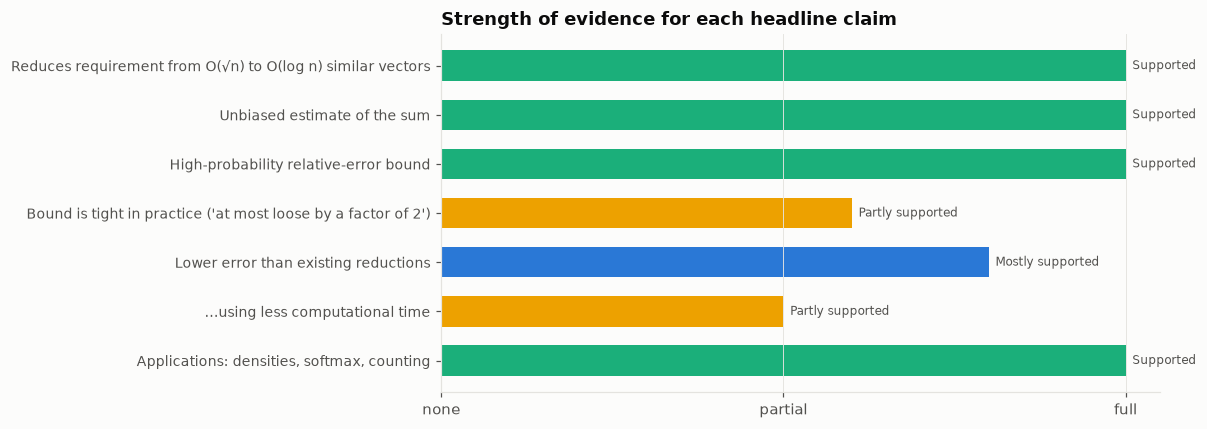

Claim (Abstract / Intro),Where the paper backs it,Verdict
Reduces requirement from O(√n) to O(log n) similar vectors,"§3.1 Prop 3.1, §3.2, Thm 3.2",Supported
Unbiased estimate of the sum,§3.2 (one-line argument),Supported
High-probability relative-error bound,"§3.3, App A",Supported
Bound is tight in practice ('at most loose by a factor of 2'),"§4.6, Fig 2b (synthetic only)",Partly supported
Lower error than existing reductions,"§4.6, Fig 3 (4 of 5 panels)",Mostly supported
…using less computational time,Fig 3 only; no runtime theory (§6); 3b is a tie,Partly supported
"Applications: densities, softmax, counting","§4.1, Figs 3-4",Supported


In [22]:
claims = pd.DataFrame([
    ("Reduces requirement from O(√n) to O(log n) similar vectors", "§3.1 Prop 3.1, §3.2, Thm 3.2", "Supported", 1.0),
    ("Unbiased estimate of the sum", "§3.2 (one-line argument)", "Supported", 1.0),
    ("High-probability relative-error bound", "§3.3, App A", "Supported", 1.0),
    ("Bound is tight in practice ('at most loose by a factor of 2')", "§4.6, Fig 2b (synthetic only)", "Partly supported", .6),
    ("Lower error than existing reductions", "§4.6, Fig 3 (4 of 5 panels)", "Mostly supported", .8),
    ("…using less computational time", "Fig 3 only; no runtime theory (§6); 3b is a tie", "Partly supported", .5),
    ("Applications: densities, softmax, counting", "§4.1, Figs 3-4", "Supported", 1.0),
], columns=["Claim (Abstract / Intro)", "Where the paper backs it", "Verdict", "score"])
fig, ax = plt.subplots(figsize=(11, 4))
y = np.arange(len(claims))[::-1]
vc = {"Supported": C["aqua"], "Mostly supported": C["blue"], "Partly supported": C["yellow"]}
ax.barh(y, claims.score, color=claims.Verdict.map(vc), height=.62)
ax.set_yticks(y, claims["Claim (Abstract / Intro)"], fontsize=9); ax.set_xlim(0, 1.05)
ax.set_xticks([0, .5, 1], ["none", "partial", "full"]); ax.grid(axis="y", visible=False)
for yi, (_, r) in zip(y, claims.iterrows()):
    ax.text(r.score + .01, yi, r.Verdict, va="center", fontsize=8, color=C["ink2"])
ax.set_title("Strength of evidence for each headline claim")
plt.tight_layout(); plt.show()
claims.drop(columns="score").style.hide(axis="index")

### 5c. Figures and captions

In [23]:
cap = captions.copy()
cap["words"] = cap.text.map(lambda s: len(L.words(s)))
cap["figure"] = cap.text.str.extract(r"^((?:Figure|Table) \d)")
first_ref = {}
for _, r in sen.iterrows():
    for m in re.finditer(r"(Figure|Table) (\d)", r.text):
        first_ref.setdefault(f"{m.group(1)} {m.group(2)}", r.sid)
cap["first referenced in"] = cap.figure.map(first_ref).fillna("never")
cap["placed in"] = cap.sid
cap["self-contained?"] = ["no – references proof terms (U, ℓ*)", "yes", "yes", "no – title only, no takeaway", "yes", "yes"][:len(cap)]
cap[["figure", "placed in", "first referenced in", "words", "self-contained?"]].style.hide(axis="index")

figure,placed in,first referenced in,words,self-contained?
Figure 1,2,3.1,52,"no – references proof terms (U, ℓ*)"
Figure 2,4.5,4.6,36,yes
Figure 3,5,4.6,66,yes
Table 1,B,never,6,"no – title only, no takeaway"
Figure 4,C,C,59,yes
Figure 5,C,C,38,yes


- **Table 1 is never referenced by name.** Appendix C says "See *Figure 1* for the recall values for TopK without levels", which should be **Table 1**.
- Figure 1 sits in Section 2 but explains the proof in 3.1. Figure 3, the paper's key result figure, floats into Related Work.
- Captions are generally informative. They state what is plotted *and* how the confidence intervals were computed, which experts appreciate. They rarely state the **takeaway** ("Our method is the only one with low error across the whole flat-to-peaky range"). A one-sentence conclusion in each caption would help skimmers, who often read only the figures.

### 5d. Copy-edit list (found by a full read, plus an automatic duplicate-word check)

Automatic duplicate-word hits: [('4.6', 'when when')]


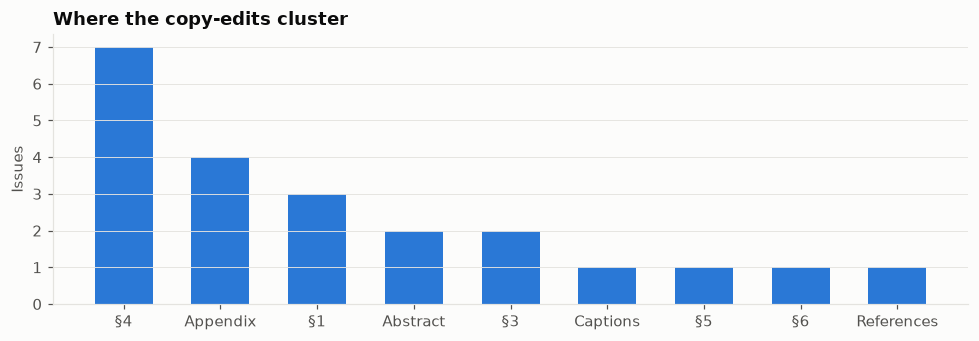

Where,As written,Suggested
Abstract,vector similar search implementation,vector similarity search implementation
Abstract,OpenImages,Open Images (match body text)
§1 ¶1,there has been significant advances,there have been significant advances
§1 roadmap,analyze our algorithm in Section 3 We then,…in Section 3. We then
§1 roadmap,a opportunities and limitations,opportunities and limitations
§3.3,"This will later allow us to lower bound pᵢ , Our main step",…lower bound pᵢ. Our main step
§3.3 Lemma 3.6,positive and monotonically nondecreasing,non-increasing (fᵢ are sorted in decreasing order)
§4.1,the bandwidth parameters that controls,the bandwidth parameter that controls
§4.2,which is Vision Transformer (ViT),which is a Vision Transformer (ViT)
§4.3,The Flick30k dataset,The Flickr30k dataset


In [24]:
dups = [(r.sid, m.group(0)) for _, r in sen.iterrows() for m in re.finditer(r"\b(\w+) \1\b", r.text, re.I)]
edits = pd.DataFrame([
    ("Abstract", "vector similar search implementation", "vector similarity search implementation"),
    ("Abstract", "OpenImages", "Open Images (match body text)"),
    ("§1 ¶1", "there has been significant advances", "there have been significant advances"),
    ("§1 roadmap", "analyze our algorithm in Section 3 We then", "…in Section 3. We then"),
    ("§1 roadmap", "a opportunities and limitations", "opportunities and limitations"),
    ("§3.3", "This will later allow us to lower bound pᵢ , Our main step", "…lower bound pᵢ. Our main step"),
    ("§3.3 Lemma 3.6", "positive and monotonically nondecreasing", "non-increasing (fᵢ are sorted in decreasing order)"),
    ("§4.1", "the bandwidth parameters that controls", "the bandwidth parameter that controls"),
    ("§4.2", "which is Vision Transformer (ViT)", "which is a Vision Transformer (ViT)"),
    ("§4.3", "The Flick30k dataset", "The Flickr30k dataset"),
    ("§4.3", "with train dataset having about 20,000 classes", "with the train set having about 20,000 classes"),
    ("§4.4", "and the use the unbiased estimate", "and then use the unbiased estimate"),
    ("§4.5", "randomly sample human-provided captions", "randomly sampled human-provided captions"),
    ("§4.6", "low error when when f is", "low error when f is"),
    ("Fig 3 caption", "so it is cutoff in the plot", "so they are cut off in the plot"),
    ("§5", "hashing-based estimators Charikar and Siminelakis (2017)", "hashing-based estimators (Charikar and Siminelakis, 2017)"),
    ("§6", "find a (approximate) most similar vector", "find an (approximate) most similar vector"),
    ("App A title", "Proofs of a select number of lemmas", "Proofs of selected lemmas"),
    ("App A.3 title", "Restatement Bernstein's inequality", "Restatement of Bernstein's inequality"),
    ("App A.3", "Dzhaparidze and Van Zanten (2001) cites", "…cite"),
    ("App C", "See Figure 1 for the recall values for TopK", "See Table 1 …"),
    ("References", "Open Images dataset v4 (title) vs v7 (text)", "Check which version was used"),
], columns=["Where", "As written", "Suggested"])
print("Automatic duplicate-word hits:", dups)
fig, ax = plt.subplots(figsize=(9, 3.2))
cnt = edits.Where.str.extract(r"^(Abstract|§\d|App|Fig|References)")[0].replace({"App": "Appendix", "Fig": "Captions"}).value_counts()
ax.bar(cnt.index, cnt.values, color=C["blue"], width=.6); ax.set_ylabel("Issues"); ax.grid(axis="x", visible=False)
ax.set_title("Where the copy-edits cluster")
plt.tight_layout(); plt.show()
edits.style.hide(axis="index")

---
# 6. Conclusions

### The style in one paragraph
The paper is written in a **lean, confident, engineer-mathematician style**. Sentences are short by academic standards (main-text mean 17.5 words). The voice is active and first-person ("we"), the vocabulary is precise and consistently reused, and the claims are measured: boosters are technical, not promotional, and the limitations are stated candidly. Its weaknesses come from **economy rather than excess**. The core method is compressed into about 380 words, the best intuition ("peaky vs flat") is held back until Section 4, the paper ends without a conclusion, and about 20 copy-level slips suggest a final proofreading pass was skipped.

### Scorecard

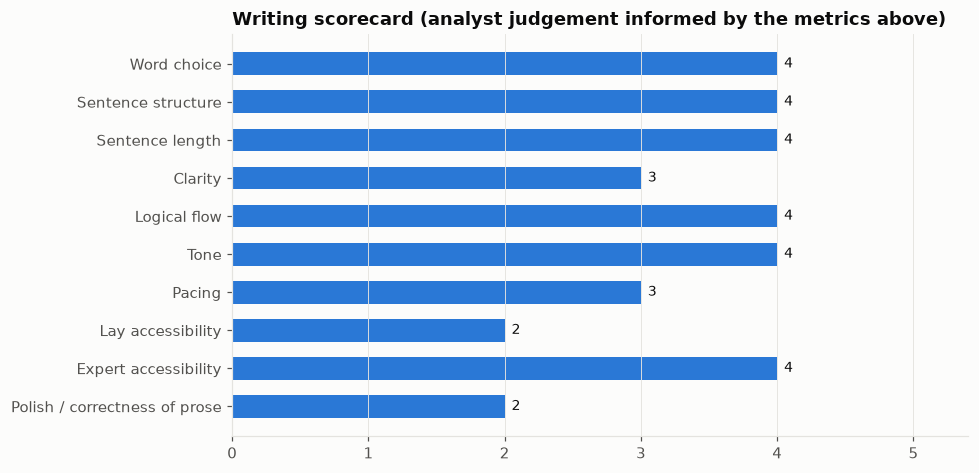

Dimension,Score (1-5),Why
Word choice,4,"Precise, consistent terms; minimal puffery. Heavy repetition of 'vector similarity search'; CLIP/BERT unexpanded."
Sentence structure,4,"Short, active, first-person. A handful of 35-50-word citation trains and clause chains."
Sentence length,4,Mean 16 (all) / 17.5 (main text); good variety. Abstract/Discussion run long.
Clarity,3,Precise for experts; abrupt jump into notation in §2; key intuition arrives late.
Logical flow,4,Clean problem→idea→proof→experiments arc; every contribution backed; figures misplaced; no conclusion.
Tone,4,"Confident, honest, collegial. 'Simple' over-used; a few contractions."
Pacing,3,"Concept-dense opening, very fast method, slow proof, abrupt ending."
Lay accessibility,2,Readable only in §4 and §6; abstract/intro assume ML literacy.
Expert accessibility,4,Efficient: an expert gets the whole idea in ~2 pages.
Polish / correctness of prose,2,"~20 typos/grammar slips, one wrong cross-reference, inconsistent spellings."


In [25]:
score = pd.DataFrame([
    ("Word choice", 4, "Precise, consistent terms; minimal puffery. Heavy repetition of 'vector similarity search'; CLIP/BERT unexpanded."),
    ("Sentence structure", 4, "Short, active, first-person. A handful of 35-50-word citation trains and clause chains."),
    ("Sentence length", 4, "Mean 16 (all) / 17.5 (main text); good variety. Abstract/Discussion run long."),
    ("Clarity", 3, "Precise for experts; abrupt jump into notation in §2; key intuition arrives late."),
    ("Logical flow", 4, "Clean problem→idea→proof→experiments arc; every contribution backed; figures misplaced; no conclusion."),
    ("Tone", 4, "Confident, honest, collegial. 'Simple' over-used; a few contractions."),
    ("Pacing", 3, "Concept-dense opening, very fast method, slow proof, abrupt ending."),
    ("Lay accessibility", 2, "Readable only in §4 and §6; abstract/intro assume ML literacy."),
    ("Expert accessibility", 4, "Efficient: an expert gets the whole idea in ~2 pages."),
    ("Polish / correctness of prose", 2, "~20 typos/grammar slips, one wrong cross-reference, inconsistent spellings."),
], columns=["Dimension", "Score (1-5)", "Why"])
fig, ax = plt.subplots(figsize=(9, 4.4))
y = np.arange(len(score))[::-1]
ax.barh(y, score["Score (1-5)"], color=C["blue"], height=.6)
for yi, v in zip(y, score["Score (1-5)"]): ax.text(v + .05, yi, str(v), va="center", fontsize=9)
ax.set_yticks(y, score.Dimension); ax.set_xlim(0, 5.4); ax.set_xticks(range(6)); ax.grid(axis="y", visible=False)
ax.set_title("Writing scorecard (analyst judgement informed by the metrics above)")
plt.tight_layout(); plt.show()
score.style.hide(axis="index")

### Top recommendations, in priority order
1. **Fix the copy-edits in 5d** (about 30 minutes of work, the largest gain in perceived quality). Above all, fix *Figure 1 → Table 1* in Appendix C and *nondecreasing → non-increasing* in Lemma 3.6, which is a mathematical, not cosmetic, slip.
2. **Move the "peaky vs flat" intuition into the Introduction.** Two sentences would do: "Top-k works when a few items dominate the sum; random sampling works when contributions are even; our levels interpolate automatically." This is the single biggest clarity win for every audience.
3. **Add a plain-language bridge before Section 2**, such as: "Think of each level as a progressively thinner random subsample: level 1 holds half the data, level 2 a quarter … The top results from each level tell us about both the heavy hitters and the long tail." This softens the notation cliff.
4. **Add a short Conclusion** restating the result (O(log n) vs O(√n), unbiased, bound within 2× of empirical) and the main limitation.
5. **Temper "less computational time" in the Abstract** to match the evidence, for example "lower error at equal or lower computational time in four of five settings".
6. **Split the 35+-word sentences** listed in 1a, especially the maximization-oracle definition in the Introduction and the HNSW sentence in Section 6, and break up the opening sentence's 11-reference citation train.
7. **Relocate Figures 1 and 3** next to their first references, and add a one-line takeaway to each caption.
8. **Standardise terminology** (5a), expand CLIP and BERT once, and move licence details out of the running text.